### First figures  

* histogram plot showing the number of documents over the years
* histogram plot showing which are most common in the prediction set
* a map of the locations of the infrastrucutre damages 





In [1]:
import os
import sys
from pathlib import Path
import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sys.path.append('../')
from src.settings import settings as s
import src.document_cleaning as dc
import src.translation_model as tm
import src.utils as u
import src.datahandler as dh
import src.postprocess as pp
import src.visualization as v

# login to HF
# NOTE raises exception when env.variable does not exist (compared to os.envrion.get and its shortcut os.getenv)
os.getenv("HUGGINGFACE_TOKEN")

#  automatic linebreaks and multi-line cells.
pd.set_option("display.colheader_justify", "left")
pd.set_option('display.max_colwidth', 5000)


# set working dir
print("Running on local machine")
os.chdir("/home/a-buch/Documents/TUB_DWN/_PROJECTS/CI-impacts-information-retrieval/")

# HF directory
HF_HOME_DIR: str = "/home/a-buch/Documents/TUB_DWN/_PROJECTS/CI-impacts-information-retrieval/notebooks/huggingface_mirror/hub"
HF_TOKEN_PATH: str = "/home/a-buch/Documents/TUB_DWN/_PROJECTS/CI-impacts-information-retrieval/notebooks/huggingface_mirror/token"

# step = "step2"
step = "judge"


Running on local machine
Running on local machine


/home/a-buch/Documents/TUB_DWN/_PROJECTS/CI-impacts-information-retrieval/.venv/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/a-buch/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package punkt_tab to /home/a-buch/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Running on local machine


In [2]:
## data to plot


#  Define data dir where tags.csv and domain-expertise derived tag lists are found 
# VALID_DATA_FILENAME = s.VALID_DATA_FILENAME
VALID_DATA_FILENAME = "table_ci_impacts_sm_casc_hpc.csv"
PATH_VALID_DATA = s.PATH_VALID_DATA

s.LLM_DATA_FILENAME = f"df_responses_{step}_ner_geollm.csv"
LLM_DATA_FILEPATH = Path(s.PATH_LLM_DATA / s.LLM_DATA_FILENAME)

df_valid_org = pd.read_csv(
    PATH_VALID_DATA / VALID_DATA_FILENAME,
    # usecols=["publication_id", "ci1_type", "ci1_damage", "ci1_location", "sentence_reference"],
)
print(len(df_valid_org))
## pre-process: 
# remove undone entries
df_valid_org = df_valid_org[~df_valid_org.astype(str).apply(lambda x: x.str.contains("xx")).any(axis=1)]
# remove further location info (e.g. that entry is a town, Landkreis, Bavaria etc.)
# df_valid_org["ci1_location"] = df_valid_org["ci1_location"].replace(r"\s*\(.*\)", "", regex=True).str.strip()
df_valid_org = df_valid_org.dropna(subset=["publication_id"], how="all") # drop rows where citation info is missing
print(len(df_valid_org))
print(df_valid_org.publication_id.unique())

df_valid = df_valid_org

print(f"Collecting LLM responses from {step}")
# ## prediction data
# df_pred = pd.read_csv(
#     LLM_DATA_FILEPATH,
#    # usecols=["citation_id", "chunk_id", "infrastructure_type", "damage", "location", "chunk_text"]
# )
df_pred = pd.DataFrame()
# for i, file in enumerate(glob.glob(os.path.join(s.PATH_DATA, "llm_outputs/responses_single_docs", f'*{step}*.csv'))):
for i, file in enumerate(glob.glob(os.path.join("../interim_results_debug_26oct", f'llm_*chain_{step}*.csv'))):
    print(i, file)
    try:
        df_pred = pd.concat([df_pred, pd.read_csv(file)], ignore_index=True)
    except:
        print("Could not load:", file)

# df_pred = pd.read_csv("/home/a-buch/Documents/TUB_DWN/_PROJECTS/interim_results_debug/llm_geollm_chain_step1_Koks 2022.csv")


397
342
<ArrowStringArray>
[                            'ABC 2024',
 'not clear if this affected trnasport',
                         'Artemis 2015',
                           'Brown 2010',
                   'Containerlift 2024',
                          'Deidda 2025',
                             'EFE 2024',
                        'Euronews 2024',
        'European Investment Bank 2025',
                         'Ferlita 2023',
               'Gilbody Dickerson 2024',
                     'Karakatsani 2023',
                            'Kaur 2025',
                          'Kettle 2020',
                            'Nour 2011',
                          'Chamra 2006',
                        'Mitsakis 2014',
                       'Pescaroli 2017',
                          'Hladny 2004',
                            'Fink 2009',
                          'Keller 2014',
                          'Khazai 2013',
                            'Zeit 2021',
                            'K

In [3]:
df_pred.info()


<class 'pandas.DataFrame'>
RangeIndex: 1105 entries, 0 to 1104
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   is_infrastructure_case          1105 non-null   bool  
 1   infrastructure_type             1105 non-null   str   
 2   infrastructure_amount           157 non-null    object
 3   location                        907 non-null    str   
 4   damage                          940 non-null    str   
 5   economic_impact_type            161 non-null    object
 6   economic_impact_origin          145 non-null    object
 7   economic_impact_amount          79 non-null     object
 8   economic_impact_unit            79 non-null     object
 9   societal_impact_origin          179 non-null    object
 10  societal_impact_type            161 non-null    object
 11  societal_impact_amount          82 non-null     object
 12  societal_impact_unit            75 non-null     object
 13 

In [4]:
ci_patterns = pd.read_json("./ner_patterns.jsonl/patterns", lines=True)


## group Ci types into CI groups and CI sectors
# if not "infrastructure_group" in df_pred.columns or df_pred["infrastructure_group"].isna().any():
df_pred[["infrastructure_group", "infrastructure_sector", "secondary_infrastructure_group", "secondary_infrastructure_sector"]] = None
df_pred = pp.group_ci_types(df_pred, "infrastructure_type", "infrastructure_group", ci_patterns)
df_pred = pp.group_ci_types(df_pred, "infrastructure_type", "infrastructure_sector", ci_patterns, grouping_scheme="sector")
df_pred = pp.group_ci_types(df_pred, "secondary_infrastructure_asset", "secondary_infrastructure_group", ci_patterns)
df_pred = pp.group_ci_types(df_pred, "secondary_infrastructure_asset", "secondary_infrastructure_sector", ci_patterns,  grouping_scheme="sector")

# if not "ci1_group" in df_valid.columns or df_valid["ci1_group"].isna().any():
df_valid[["infrastructure_group", "infrastructure_sector", "secondary_infrastructure_group", "secondary_infrastructure_sector"]] = None
df_valid = pp.group_ci_types(df_valid, "ci1_type", "infrastructure_group", ci_patterns)
df_valid = pp.group_ci_types(df_valid, "infrastructure_group", "infrastructure_sector", ci_patterns,  grouping_scheme="sector")
df_valid = pp.group_ci_types(df_valid, "secondary_infrastructure_asset", "secondary_infrastructure_group", ci_patterns)
df_valid = pp.group_ci_types(df_valid, "secondary_infrastructure_group", "secondary_infrastructure_sector", ci_patterns,  grouping_scheme="sector")


# see which could not be grouped
# df_plot[df_plot.secondary_infrastructure_group.isna() & ~ df_plot.secondary_infrastructure_asset.isna()]


# df_plot["secondary_infrastructure_sector"] = df_plot["secondary_infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# # # print(df_plot["secondary_infrastructure_group"].unique())
# df_plot["secondary_infrastructure_sector"] = df_plot["secondary_infrastructure_sector"].str.split(" - ").str[0]




### figure labels

In [5]:
# ## nice labeling for CI

# cigroup_labels = {
#     "airports" : "Transportation - Aviation",
#     "aviation" : "Transportation - Aviation",
#     "roads" : "Transportation - Road network",
#     "road_others" : "Transportation - Road network",
#     "bridges" : "Transportation - Bridges",
#     "motorways" : "Transportation - Highways / Motorways",
#     "rail" : "Transportation - Rail network",
#     "railway_station":  "Transportation - Rail network",
#     "rail_service":  "Transportation - Rail service",
#     "metro" :  "Transportation - Rail network",
#     "ports" : "Transportation - Shipping traffic",
#     "waterways_ships" : "Transportation - Shipping traffic",
#     "maritime" : "Transportation - Shipping traffic",
#     "inland_waterways" : "Transportation - Inland shipping",
#     "transport_others": "Transportation - Transportation (not further specified)",
#     "transport_service": "Transportation - Transportation (not further specified)",
#     "transport_general": "Transportation - Transportation (not further specified)",

#     "water_distribution" : "Water - Water network",
#     "water_others" : "Water - Water network",
#     "water_supply" : "Water - Water supply",
#     "waterprotection" : "Structural protection measures - Flood protection",

#     "electricity_distribution" :  "Energy - Electricity network",
#     "electricity_others" : "Energy - Electricity network",
#     "power_plants" : "Energy - Electricity network",
#     "nonrenewable_others" : "Energy - Non-renewable energy",
#     "renewable" : "Energy - Renewable energy",
#     "petrol_gas_stations_consumers" :  "Energy - Electricity supply",
#     "electricity_supply" : "Energy - Electricity supply",

#     "gas_distribution" : "Energy - Gas network",
#     "gas_storage" : "Energy - Gas network",
#     "gas_supply" : "Energy - Gas supply",

#     "wastewater" : "Waste - Wastewater",
#     "waste_others" : "Waste - Waste (not further specified)",
#     "waste_treatment" : "Waste - Waste treatment",

#     "it_telecommunication" : "IT / communication - IT / communication (not further specified)", #Not specified",
#     "it_telecom_distribution" : "IT / communication - IT / communication (distribution)",
#     "it_telecom_supply" : "IT / communication - IT / communication (supply)", 

#     "industry_heavy": "Industry - Chemical or heavy industry",

#     "healthcare_others" : "Social - Healthcare (not further specified)", # Not specified",
#     "healthcare_general" : "Social - Healthcare (not further specified)", # Not specified",
#     "healthcare_hospitals_clinics" : "Social - Hospitals / clinics",
#     "healthcare_clinics" : "Social - Hospitals / clinics",
#     "education_kita" : "Social - Day care centres",
#     "education_school" : "Social - Schools",
#     "education_others" :  "Social - Education (not further specified)",
# }


### Donut plot -  most common CI in validation + prediction set


In [61]:

def figure_donuts(df_plot:pd.DataFrame, col_labels: str, col_sizes:str, col_groups: str, base_palettes:dict, startangle:int=170):


    # --- Seaborn style ---
    sns.set_theme(style="white", context="talk")


    groups = df_plot[col_groups]
    # labels = df_plot[col_labels]
    # sizes = df_plot[col_sizes]
    

    ## Sector colors
    unique_sectors = groups.unique()

    sector_palettes = {}

    for sector in unique_sectors:
        n = (groups == sector).sum()
        palette_name = base_palettes.get(sector, "Greys")

        # soft gradient (skip very light colors)
        palette = sns.color_palette(palette_name, n + 3)[2:]
        sector_palettes[sector] = palette

    # Assign colors
    colors = []
    counters = {s: 0 for s in unique_sectors}
    for s in groups:
        colors.append(sector_palettes[s][counters[s]])
        counters[s] += 1


    ## Sectors
    sizes_with_gaps = []
    colors_with_gaps = []
    meta = []  # 🔥 keeps mapping to original data
    labels_with_gaps = []


    ## Gap between sectors
    gap_fraction = 0.04
    gap_size = df_plot[col_sizes].sum() * gap_fraction

    for sector in unique_sectors:
        sector_df = df_plot[df_plot[col_groups] == sector]

        for j, (_, row) in enumerate(sector_df.iterrows()):
            sizes_with_gaps.append(row[col_sizes])
            colors_with_gaps.append(sector_palettes[sector][j])

            meta.append({
                "label": row[col_labels], #.split(" - ")[1],
                "size": row[col_sizes],
                "color": sector_palettes[sector][j],
                "is_gap": False
            })

        # ✅ equal gap (NOT proportional anymore)
        sizes_with_gaps.append(gap_size)
        colors_with_gaps.append((1, 1, 1, 1))

        meta.append({"is_gap": True})


    # Now rebuild colors in same order
    colors_with_gaps = []
    for sector in unique_sectors:
        sector_df = df_plot[df_plot[col_groups] == sector]
        for i in range(len(sector_df)):
            colors_with_gaps.append(sector_palettes[sector][i])
        colors_with_gaps.append((1, 1, 1, 1))  # gap color


    ####### INNER RING 

    # --- Build INNER ring (sector level, aligned with gaps) ---
    inner_sizes = []
    inner_colors = []

    for sector in unique_sectors:
        sector_df = df_plot[df_plot[col_groups] == sector]

        # total size of sector
        sector_total = sector_df[col_sizes].sum()

        # ONE slice for the sector
        inner_sizes.append(sector_total)

        # pick representative color (middle of palette)
        palette = sector_palettes[sector]
        inner_colors.append(palette[len(palette) // 2])

        # SAME gap as outer ring
        # gap_size = sector_total * gap_fraction
        inner_sizes.append(gap_size)
        inner_colors.append((1, 1, 1, 1))  # white gap
    ########

    # sizes_with_gap = list(df_plot["count"]) + [gap_size]
    # colors_with_gap = colors + [(1, 1, 1, 0)]  # fully transparent



    #####                     PLOT                      ####  
    
    # Startangle of donut
    startangle = startangle # 170 #- (gap_size / sum(sizes_with_gaps)) * 180
    
    
    #####                     PLOT  OUTER DONUT                      ####  

    fig, ax = plt.subplots(figsize=(20, 25))

    ## Actual donut chart
    wedges, _ = ax.pie(
        sizes_with_gaps,
        colors=colors_with_gaps,
        startangle=startangle,
        wedgeprops=dict(width=0.12, edgecolor="white", linewidth=2)
    )

    # # --- Leader lines at END of each segment ---
    # real_wedges = wedges[:-1]
    real_indices = [i for i, lbl in enumerate(labels_with_gaps) if lbl is not None]
    real_wedges = [wedges[i] for i in real_indices]


    # --- Collect positions first ---

    label_data = []

    for i, wedge in enumerate(wedges):
        if meta[i]["is_gap"]:
            continue  # 🔥 skip gaps safely

        angle = wedge.theta2 - 0.3
        rad = np.deg2rad(angle)

        x, y = np.cos(rad), np.sin(rad)

        start = (x * 1.0, y * 1.0)
        mid = (x * 1.25, y * 1.25)

        end_x = 1.35 if x > 0 else -1.35
        text_x = end_x + 0.08 if x > 0 else end_x - 0.08

        label_data.append({
            "i": i,
            "start": start,
            "mid": mid,
            "end_x": end_x,
            "text_x": text_x,
            "end_y": mid[1],
            "side": "right" if x > 0 else "left"
        })

    # Split left/right
    left = [d for d in label_data if d["side"] == "left"]
    right = [d for d in label_data if d["side"] == "right"]

    import src.visualization as v

    left = v.adjust_positions(left)
    right = v.adjust_positions(right)

    # Merge back
    label_data = left + right

    # # --- Draw lines + labels ---
    for d in label_data:
        i = d["i"]
        m = meta[i]

        align = "left" if d["side"] == "right" else "right"

        ax.plot([d["start"][0], d["mid"][0]],
                [d["start"][1], d["mid"][1]],
                color=m["color"], lw=4)

        ax.plot([d["mid"][0], d["end_x"]],
                [d["mid"][1], d["end_y"]],
                color=m["color"], lw=4)

        ax.text(
            d["text_x"],
            d["end_y"],
            f"{m['label']} [n={m['size']}]",
            ha=align,
            va="center",
            fontsize=25
        )

        # Anchor point on donut (slightly outside ring)
        anchor_x = d["start"][0] * 1.01
        anchor_y = d["start"][1] * 1.01
        ax.scatter(anchor_x, anchor_y, color=m["color"], s=35, zorder=30)

        
    ####### PLOT INNER

    # --- INNER ring (sectors) ---
    wedges_inner, _ = ax.pie(
        inner_sizes,
        radius=0.85,   # smaller than outer, 
        colors=inner_colors,
        startangle=startangle,  # MUST match outer ring
        wedgeprops=dict(width=0.30, edgecolor="white", linewidth=0) # inner ring thickness etc
    )

    for i, wedge in enumerate(wedges_inner):
        # skip gap slices (every second entry)
        if i % 2 == 1:
            continue

        angle = (wedge.theta1 + wedge.theta2) / 2
        rad = np.deg2rad(angle)

        x, y = np.cos(rad), np.sin(rad)

    plt.show()


In [62]:
df_pred.citation_id.unique()

<ArrowStringArray>
[             'Papaioannou 2026',                 'McGregor 2007',
               'Nieuwsblad 2021',                    'Prack 2020',
                  'Clapson 2021',                      'AFP 2022',
                     'UNEP 2013',                   'Chamra 2006',
 'European Investment Bank 2025',                  'Manhold 2021',
                'Krausmann 2014',                     'Fink 2004',
                     'Kaur 2025',             'Handelsblatt 2023',
                   'Wilson 2024',               'Grieshaber 2026',
                     'Zeit 2021',                     'Zeit 2026',
                    'AEMET 2024',                    'Brown 2010',
            'Containerlift 2024',                  'Tempest 2019',
                   'Fekete 2025',                'Wildhagen 2013',
                'Skoulding 2023',                 'Bergrath 2021',
                     'Mohr 2022',                  'Reuters 2023',
             'The Guardian 2018',          

In [63]:
# df_pred.infrastructure_group.unique()
df_pred.infrastructure_sector.value_counts()

infrastructure_sector
Transportation                    686
Energy                            169
Water                              91
Health                             59
Waste                              27
IT / Communication                 16
Structural Protection Measures     12
Heavy Industry                     10
Education                           7
Energy / Communication              1
Name: count, dtype: int64

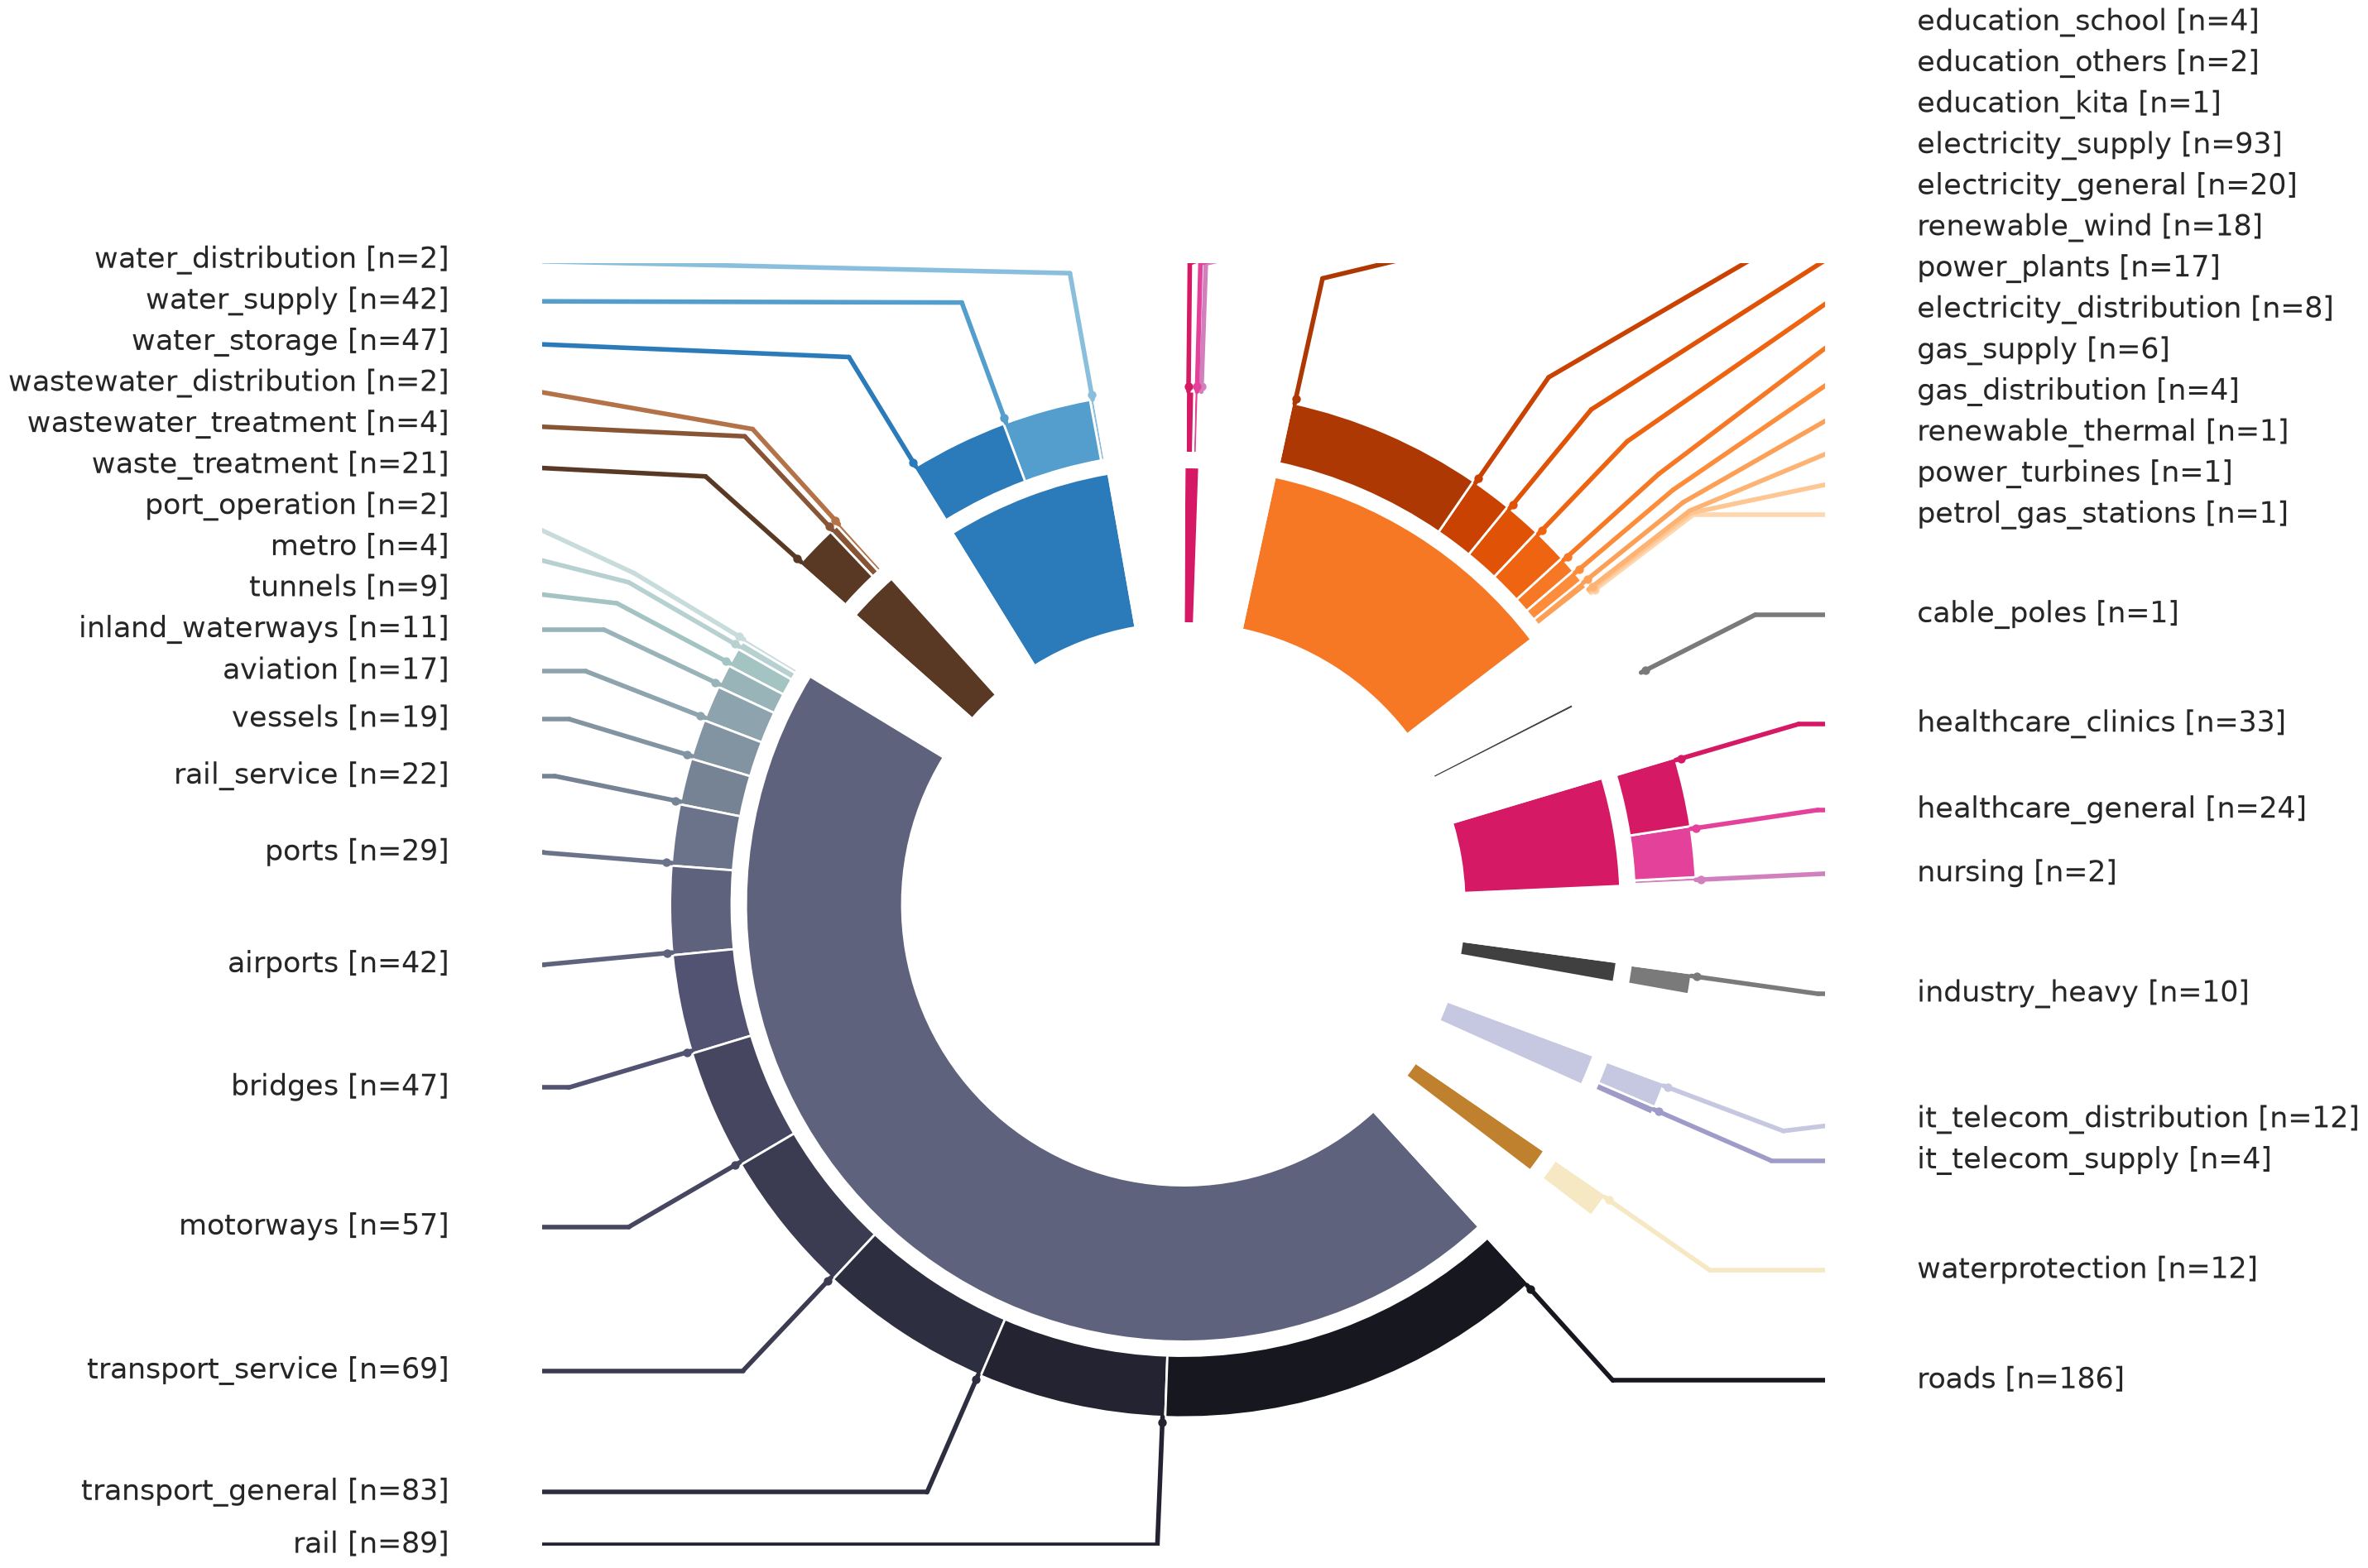

0

In [64]:

base_palettes = {
    "Transportation": "bone_r", #"Greys",
    "Energy": "Oranges",
    "Water": "Blues",
    "Structural Protection Measures": "BrBG_r", # "cividis_d", # "Greens_d",
    "Waste": "copper_r",
    "Health": "PuRd",
    "Education": "PuRd",
    "Other": "Greys_r",
    "IT / Communication": "Purples_r",
    "gap": "Black"  # for the gap piece
}


# ## VALID
# df_plot = df_valid.copy(deep=True)

# ## Prep - create sector and subsector ("group") columns with nice labels 
# print(df_plot["ci1_group"].unique())
# df_plot["ci1_group"] = df_plot["ci1_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# df_plot["ci1_sector"] = df_plot["ci1_group"].str.split(" - ").str[0]

# #  Aggregate and sort data ---
# df_plot = (
#     df_plot.groupby(["ci1_sector", "ci1_group"]).size().reset_index(name="count")
# )
# # Sort by group then value (important for visual grouping)
# df_plot = df_plot.sort_values(
#     ["ci1_sector", "count"],
#     ascending=[False, True]
# )
# figure_donuts(df_plot=df_plot, col_labels= "ci1_group", col_sizes="count", col_groups="ci1_sector", base_palettes=base_palettes, startangle=201)



# ## PRED

df_plot = df_pred.copy(deep=True)

# ## Prep - create sector and subsector ("group") columns with nice labels 
# print(df_plot["infrastructure_group"].unique())
# df_plot["infrastructure_group"] = df_plot["infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# print(df_plot["infrastructure_group"].unique())
# df_plot["infrastructure_sector"] = df_plot["infrastructure_group"].str.split(" - ").str[0]


#  Aggregate and sort data ---
df_plot = (
    df_plot.groupby(["infrastructure_sector", "infrastructure_group"]).size().reset_index(name="count")
)
# Sort by group then value (important for visual grouping)
df_plot = df_plot.sort_values(
    ["infrastructure_sector", "count"],
    ascending=[False, True]
)
figure_donuts(df_plot=df_plot, col_labels= "infrastructure_group", col_sizes="count", col_groups="infrastructure_sector", base_palettes=base_palettes, startangle=100)


0

In [65]:
# df_plot.columns
df_plot.info()

<class 'pandas.DataFrame'>
Index: 42 entries, 39 to 2
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   infrastructure_sector  42 non-null     str  
 1   infrastructure_group   42 non-null     str  
 2   count                  42 non-null     int64
dtypes: int64(1), str(2)
memory usage: 2.3 KB


In [43]:
df_plot["count"].sum()

np.int64(1078)

In [31]:
# # REST - DONUT - only one ring

# import matplotlib.pyplot as plt
# import seaborn as sns


# # --- Seaborn style ---
# sns.set_theme(style="white", context="talk")

# ## Prep - create sector and subsector ("group") columns with nice labels 
# df_plot = df_pred.copy(deep=True)
# # nice lables for CI group (ie Ci subsector) and sector
# df_plot["infrastructure_group"] = df_plot["infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# df_plot["infrastructure_sector"] = df_plot["infrastructure_group"].str.split(" - ").str[0]


# # # --- Aggregate data correctly ---
# df_plot = (
#     df_plot.groupby(["infrastructure_sector", "infrastructure_group"]).size().reset_index(name="count")
# )


# # Sort by group then value (important for visual grouping)
# df_plot = df_plot.sort_values(
#     ["infrastructure_sector", "count"],
#     ascending=[False, True]
# )



# labels = df_plot["infrastructure_group"]
# sizes = df_plot["count"]
# groups = df_plot["infrastructure_sector"]
# unique_sectors = groups.unique()

# base_palettes = {
#     "Transportation": "bone_r", #"Greys",
#     "Energy": "Oranges_r",
#     "Water": "Blues_r",
#     "Structural Protection Measures": "BrBG_d", # "cividis_d", # "Greens_d",
#     "Waste": "copper_r",
#     "Education": "PuRd_r",
#     "Health": "PuRd_r",
#     "Other": "Greys_r",
#     "IT / Communication": "Purples_r",
#     "gap": "White"  # for the gap piece
# }


# ## Sector colors
# sector_palettes = {}

# for sector in unique_sectors:
#     n = (groups == sector).sum()
#     palette_name = base_palettes.get(sector, "Greys")

#     # soft gradient (skip very light colors)
#     palette = sns.color_palette(palette_name, n + 3)[2:]
#     sector_palettes[sector] = palette

# # Assign colors
# colors = []
# counters = {s: 0 for s in unique_sectors}
# for s in groups:
#     colors.append(sector_palettes[s][counters[s]])
#     counters[s] += 1


# ## Sectors
# sizes_with_gaps = []
# colors_with_gaps = []
# meta = []  # 🔥 keeps mapping to original data

# gap_fraction = 0.4

# for sector in unique_sectors:
#     sector_df = df_plot[df_plot["infrastructure_sector"] == sector]

#     for j, (_, row) in enumerate(sector_df.iterrows()):
#         sizes_with_gaps.append(row["count"])
#         colors_with_gaps.append(sector_palettes[sector][j])

#         meta.append({
#             "label": row["infrastructure_group"].split(" - ")[1],
#             "size": row["count"],
#             "color": sector_palettes[sector][j],
#             "is_gap": False
#         })

#     # add sector gap
#     gap_size = sector_df["count"].sum() * gap_fraction
#     sizes_with_gaps.append(gap_size)
#     colors_with_gaps.append((1, 1, 1, 1))

#     meta.append({
#         "is_gap": True
#     })

# # Now rebuild colors in same order
# colors_with_gaps = []
# for sector in unique_sectors:
#     sector_df = df_plot[df_plot["infrastructure_sector"] == sector]
#     for i in range(len(sector_df)):
#         colors_with_gaps.append(sector_palettes[sector][i])
#     colors_with_gaps.append((1, 1, 1, 1))  # gap color


# ## Gap piece
# # gap_size = 50 # df_plot["count"].sum() * 0.2  # controls how open it is (10–25% works well)
# gap_size = df_plot["count"].sum() * 0.3  # controls how open it is (10–25% works well)

# sizes_with_gap = list(df_plot["count"]) + [gap_size]
# colors_with_gap = colors + [(1, 1, 1, 0)]  # fully transparent


# ##### PLOT 

# fig, ax = plt.subplots(figsize=(15, 15))

# ## Actual donut chart
# wedges, _ = ax.pie(
#     sizes_with_gaps,
#     colors=colors_with_gaps,
#     startangle=170,
#     wedgeprops=dict(width=0.12, edgecolor="white", linewidth=0)
# )

# # # --- Leader lines at END of each segment ---
# # real_wedges = wedges[:-1]
# real_indices = [i for i, lbl in enumerate(labels_with_gaps) if lbl is not None]
# real_wedges = [wedges[i] for i in real_indices]


# # --- Collect positions first ---

# label_data = []

# for i, wedge in enumerate(wedges):
#     if meta[i]["is_gap"]:
#         continue  # 🔥 skip gaps safely

#     angle = wedge.theta2 - 0.4
#     rad = np.deg2rad(angle)

#     x, y = np.cos(rad), np.sin(rad)

#     start = (x * 1.0, y * 1.0)
#     mid = (x * 1.25, y * 1.25)

#     end_x = 1.35 if x > 0 else -1.35
#     text_x = end_x + 0.08 if x > 0 else end_x - 0.08

#     label_data.append({
#         "i": i,
#         "start": start,
#         "mid": mid,
#         "end_x": end_x,
#         "text_x": text_x,
#         "end_y": mid[1],
#         "side": "right" if x > 0 else "left"
#     })

# # Split left/right
# left = [d for d in label_data if d["side"] == "left"]
# right = [d for d in label_data if d["side"] == "right"]

# import src.visualization as v

# left = v.adjust_positions(left)
# right = v.adjust_positions(right)

# # Merge back
# label_data = left + right

# # # --- Draw lines + labels ---
# for d in label_data:
#     i = d["i"]
#     m = meta[i]

#     align = "left" if d["side"] == "right" else "right"

#     ax.plot([d["start"][0], d["mid"][0]],
#             [d["start"][1], d["mid"][1]],
#             color=m["color"], lw=2)

#     ax.plot([d["mid"][0], d["end_x"]],
#             [d["mid"][1], d["end_y"]],
#             color=m["color"], lw=2)

#     ax.text(
#         d["text_x"],
#         d["end_y"],
#         f"{m['label']} [{m['size']}]",
#         ha=align,
#         va="center",
#         fontsize=18
#     )

#     # Anchor point on donut (slightly outside ring)
#     anchor_x = d["start"][0] * 1.02
#     anchor_y = d["start"][1] * 1.02
#     ax.scatter(anchor_x, anchor_y, color=m["color"], s=15, zorder=3)
#     # df_plot = (
#     #     df_plot
#     #     .groupby(["infrastructure_sector", "infrastructure_group"])
#     #     .size()
#     #     .reset_index(name="count")
#     # )
    



'Water supply'

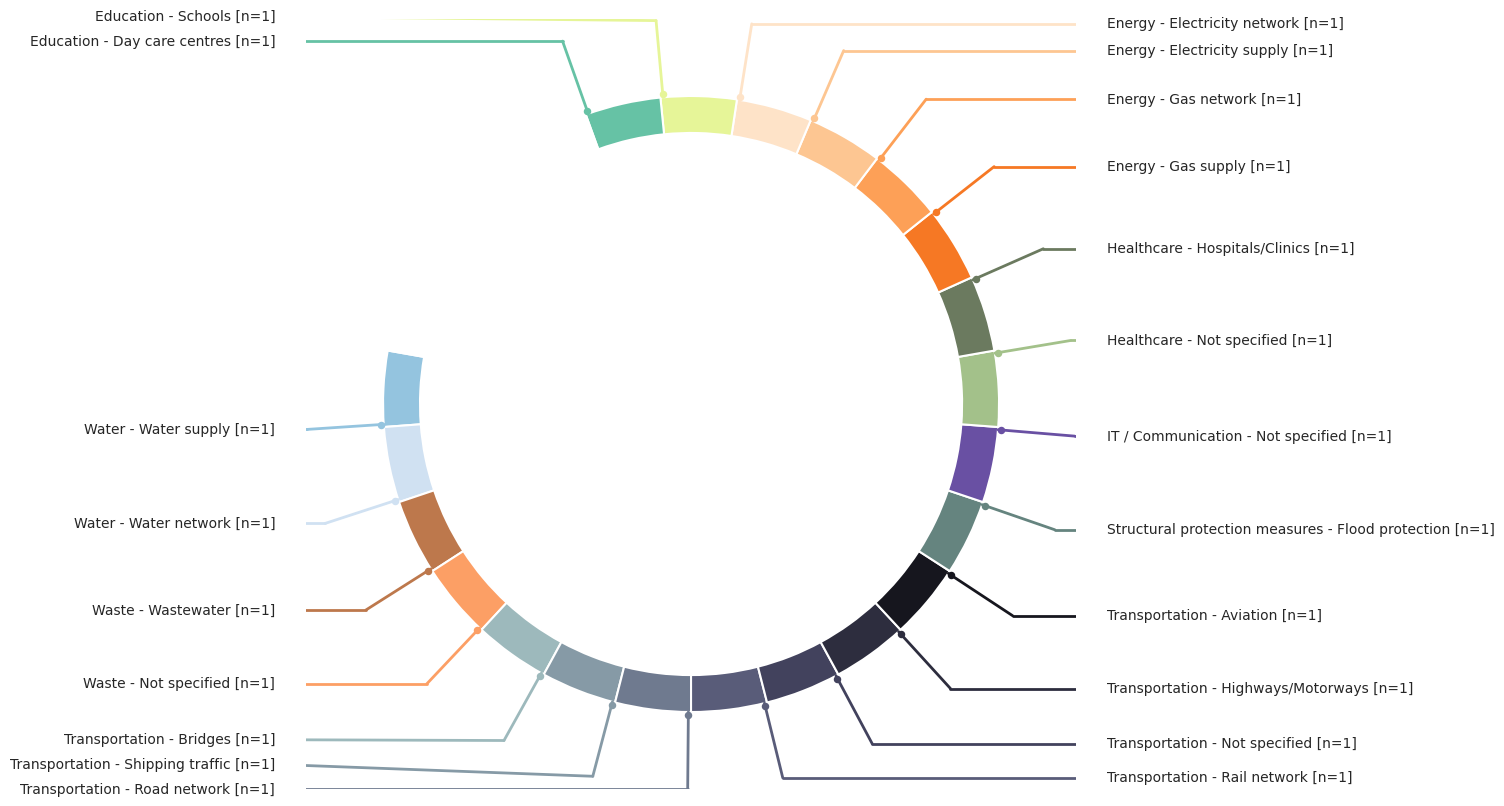

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns


# # --- Seaborn style ---
# sns.set_theme(style="white", context="talk")


# # # --- Aggregate data correctly ---
# df_plot = (
#     df_plot.groupby(["infrastructure_sector", "infrastructure_group"]).size().reset_index(name="count")
# )#.sort_values(["infrastructure_sector", "infrastructure_group"], ascending=True)


# # Sort by group then value (important for visual grouping)
# df_plot = df_plot.sort_values(
#     ["infrastructure_sector"],
#     # ["infrastructure_sector", "count"],
#     ascending=[False]
#     # ascending=[False, False]
# )
# # df_pred_plot = df_pred.groupby(["infrastructure_sector"])["infrastructure_group"].count().reset_index(name="infrastructure_group").sort_values(["infrastructure_group"], ascending=True)



# labels = df_plot["infrastructure_group"]
# sizes = df_plot["count"]
# groups = df_plot["infrastructure_sector"]
# unique_sectors = groups.unique()

# base_palettes = {
#     "Transportation": "bone_r", #"Greys",
#     "Energy": "Oranges_r",
#     "Water": "Blues_r",
#     "Structural Protection Measures": "BrBG_d", # "cividis_d", # "Greens_d",
#     "Waste": "copper",
#     "IT / Communication": "Purples",
#     "Other": "Greys",
#     "Healthcare": "Spectral_d",
#     "Education": "Spectral",
#     "gap": "White"  # for the gap piece
# }


# ## Sector colors
# sector_palettes = {}

# for sector in unique_sectors:
#     n = (groups == sector).sum()
#     palette_name = base_palettes.get(sector, "Greys")

#     # soft gradient (skip very light colors)
#     palette = sns.color_palette(palette_name, n + 2)[2:]
#     sector_palettes[sector] = palette

# # Assign colors
# colors = []
# counters = {s: 0 for s in unique_sectors}
# for s in groups:
#     colors.append(sector_palettes[s][counters[s]])
#     counters[s] += 1


# ## Sectors
# sizes_with_gaps = []
# colors_with_gaps = []
# labels_with_gaps = []

# gap_fraction = 0.04  # small gap between sectors

# for sector in unique_sectors:
#     sector_df = df_plot[df_plot["infrastructure_sector"] == sector]

#     # Add all subgroup slices (NO gaps inside)
#     for _, row in sector_df.iterrows():
#         sizes_with_gaps.append(row["count"])
#         labels_with_gaps.append(row["infrastructure_group"])
    
#     # Add ONE gap after each sector
#     gap_size = sector_df["count"].sum() * gap_fraction
#     sizes_with_gaps.append(gap_size)
#     colors_with_gaps.append((1, 1, 1, 1))  # white gap
#     labels_with_gaps.append(None)

# # Now rebuild colors in same order
# colors_with_gaps = []
# for sector in unique_sectors:
#     sector_df = df_plot[df_plot["infrastructure_sector"] == sector]
#     for i in range(len(sector_df)):
#         colors_with_gaps.append(sector_palettes[sector][i])
#     colors_with_gaps.append((1, 1, 1, 1))  # gap color


# ## Gap piece
# gap_size = df_plot["count"].sum() * 0.2  # controls how open it is (10–25% works well)

# sizes_with_gap = list(df_plot["count"]) + [gap_size]
# colors_with_gap = colors + [(1, 1, 1, 0)]  # fully transparent


# ##### PLOT 

# fig, ax = plt.subplots(figsize=(10, 10))

# ## Actual donut chart
# wedges, _ = ax.pie(
#     sizes_with_gap,          # ← use sizes WITH gap
#     colors=colors_with_gap,  # ← use colors WITH gap
#     startangle=170,          # rotate so gap is on the left
#     wedgeprops=dict(width=0.12, edgecolor="white", linewidth=1.5)
# )


# # # --- Leader lines at END of each segment ---
# real_wedges = wedges[:-1]
# # real_indices = [i for i, lbl in enumerate(labels_with_gaps) if lbl is not None]
# #real_wedges = [wedges[i] for i in real_indices]


# label_data = []

# # --- Collect positions first ---
# for i, wedge in enumerate(real_wedges):
# # for idx, wedge in zip(real_indices, real_wedges):
#     # i = idx  # use correct index
#     angle = wedge.theta2 - 0.5
#     rad = np.deg2rad(angle)

#     x, y = np.cos(rad), np.sin(rad)

#     start = (x * 1.0, y * 1.0)
#     mid = (x * 1.25, y * 1.25)

#     #Annotation placing
#     label_offset = 0.08  # small horizontal spacing from line
#     end_x = (1.35 if x > 0 else -1.35)
#     text_x = end_x + label_offset if x > 0 else end_x - label_offset
#     end_y = mid[1]
#     # end_x = 1.6 if x > 0 else -1.6
#     # end_y = mid[1]

#     side = "right" if x > 0 else "left"

#     label_data.append({
#         "i": i,
#         "start": start,
#         "mid": mid,
#         "end_x": end_x,
#         "end_y": end_y,
#         "side": side
#     })

# # Split left/right
# left = [d for d in label_data if d["side"] == "left"]
# right = [d for d in label_data if d["side"] == "right"]

# import src.visualization as v

# left = v.adjust_positions(left)
# right = v.adjust_positions(right)

# # Merge back
# label_data = left + right

# # # --- Draw lines + labels ---
# for d in label_data:
#     i = d["i"]

#     align = "left" if d["side"] == "right" else "right"


#     # redraw line to adjusted label position
#     ax.plot([d["start"][0], d["mid"][0]],
#             [d["start"][1], d["mid"][1]],
#             color=colors[i], lw=2)

#     ax.plot([d["mid"][0], d["end_x"]],
#             [d["mid"][1], d["end_y"]],
#             color=colors[i], lw=2)

#     ax.text(
#         d["end_x"],
#         d["end_y"],
#         f"{labels.iloc[i]} [n={sizes.iloc[i]}]",
#         ha=align,
#         va="center",
#         fontsize=10
#     )

#     # Anchor point on donut (slightly outside ring)
#     anchor_x = d["start"][0] * 1.01
#     anchor_y = d["start"][1] * 1.01
#     ax.scatter(anchor_x, anchor_y, color=colors[i], s=15, zorder=3)


##### a map of the locations of the infrastrucutre damages 


In [ ]:
df_plot = df_pred

In [ ]:
## get search bbox based on min and max coords
coords_list = [[float(v[0]), float(v[1])] for v in df_plot.coords.values()]
get_bbox(coords_list)

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from geopy.geocoders import Nominatim
import contextily as ctx


# df_plot = df_plot[["location", "infrastructure_group"]].dropna()

geolocator = Nominatim(user_agent="ahr_map")

def geocode(loc):
    # try:
    #     location = geolocator.geocode(f"{loc}, Germany") # this should handle also othercountires (or even regions)
    #     return Point(location.longitude, location.latitude) if location else None
    # except:
    #     return None
    try:
        location = geolocator.geocode(
            f"{loc}",
            viewbox=[Point(), Point()]
            bounded=True,
            namedetails=True   # allow vairations                          
        )  # NOTE loc needs to be in utf-8 (eg. Bad-Münsterahr)

        # location = geolocator.geocode(f"{loc}, Germany")  # NOTE loc needs to be in utf-8 (eg. Bad-Münsterahr)
        return Point(location.longitude, location.latitude) if location else None
        # location = geolocator.geocode(f"{loc}, Ahrweiler, Germany")  # NOTE loc needs to be in utf-8 (eg. Bad-Münsterahr)
        # if location:
            # return pd.Series([location.latitude, location.longitude])
    except:
        return None
        # try:
        #     # location = geolocator.geocode(f"{loc}, Spain")
        #     return Point(location.longitude, location.latitude) if location else None
        #     # if location:
        #     #     return pd.Series([location.latitude, location.longitude])
        # except:
        #     return None
        # #     #return pd.Series([None, None])
    
df_plot["geometry"] = df_plot["location"].apply(geocode)
df_points = df_plot.dropna(subset=["geometry"])


In [ ]:
gdf_points = gpd.GeoDataFrame(df_points, geometry="geometry", crs="EPSG:4326")


In [ ]:
df_plot.info()

gdf_points.location.unique()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   citation_id                143 non-null    object
 1   chunk_id                   143 non-null    object
 2   infrastructure_type        143 non-null    object
 3   infrastructure_group       143 non-null    object
 4   damage                     94 non-null     object
 5   location                   143 non-null    object
 6   ci_entity                  78 non-null     object
 7   geo_entity                 78 non-null     object
 8   coord_potential_locations  143 non-null    object
 9   chunk_text                 143 non-null    object
 10  infrastructure_type_org    130 non-null    object
 11  damage_org                 92 non-null     object
 12  locations_org              111 non-null    object
 13  coords                     94 non-null     object
 14  coords_coa

array(['Britain', 'UK', 'Spain', 'Saale', 'Rosenheim', 'Raubling',
       'Saxony-Anhalt', 'Bitterfeld', 'Den Helder', 'Utrecht',
       'Rhineland-Palatinate', 'Spa', 'Belgium', 'Netherlands', 'tracks'],
      dtype=object)

/home/a-buch/Documents/TUB_DWN/_PROJECTS/CI-impacts-information-retrieval/.venv/lib/python3.12/site-packages/contextily/tile.py:662: UserWarning: The inferred zoom level of 23 is not valid for the current tile provider (valid zooms: 0 - 19).
  warnings.warn(msg)


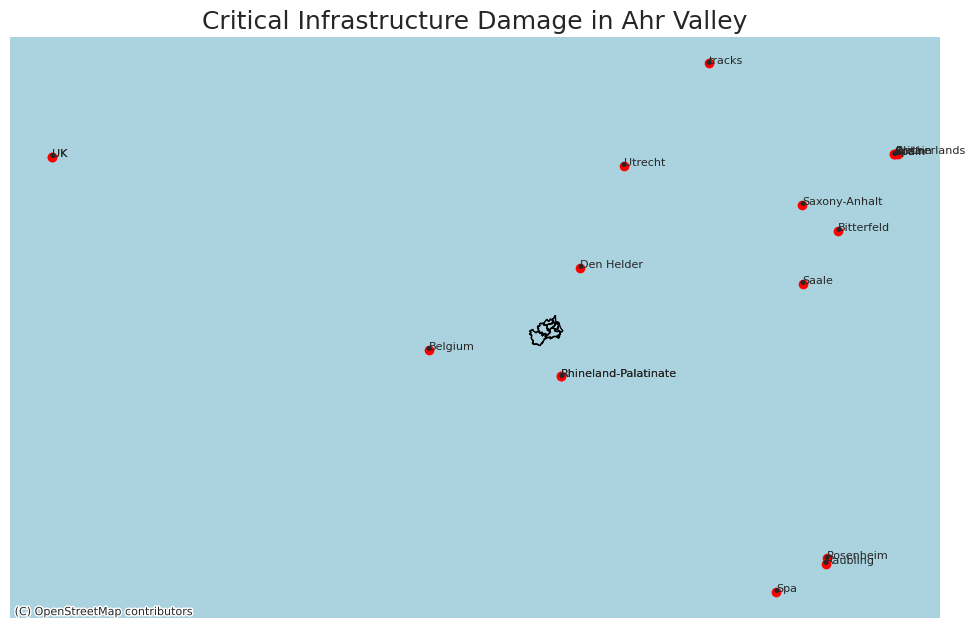

In [ ]:


# Example: load shapefile (replace gadm41_DEU_ your path)
gdf_regions = gpd.read_file("../../data/visualization/admin_borders/gadm41_DEU_3.shp") # ahrweiler, bad kissingen

# Filter to Ahr valley region (Ahrweiler district)
gdf_regions = gdf_regions[gdf_regions["NAME_2"].str.contains("Ahrweiler", na=False)]
# gdf_cities = gdf_regions[gdf_regions["NAME_3"].str.contains("Sinzig", na=False)] # example

# Spatial join: assign each point to a region
gdf_points = gdf_points.to_crs(gdf_regions.crs)

gdf_joined = gpd.sjoin(gdf_points, gdf_regions, how="left", predicate="within")

icon_map = {
    "energy": "⚡",
    "transport": "🚧",
    "water": "💧",
    "digital": "📡",
    "health": "🏥"
}

fig, ax = plt.subplots(figsize=(12, 12))

# --- Plot regions (polygons) ---
gdf_regions.boundary.plot(ax=ax, linewidth=1, color="black")

# --- Plot points ---
gdf_points.plot(ax=ax, color="red", markersize=30)

# --- Add city labels ---
for idx, row in gdf_points.iterrows():
    ax.text(
        row.geometry.x,
        row.geometry.y,
        row["location"],
        fontsize=8
    )

# --- Add infrastructure icons ---
for idx, row in gdf_points.iterrows():
    icon = icon_map.get(str(row["infrastructure_group"]).lower(), "•")

    ax.text(
        row.geometry.x,
        row.geometry.y,
        icon,
        fontsize=12,
        ha="center",
        va="center"
    )

# --- Add basemap ---
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)

ax.set_axis_off()
plt.title("Critical Infrastructure Damage in Ahr Valley")

plt.show()

In [ ]:
## clustered MAP

import pandas as pd
import folium
from folium.plugins import MarkerCluster
from geopy.geocoders import Nominatim

df_plot_2 = df_plot.copy(deep=True)

geolocator = Nominatim(user_agent="ahr_cluster_map")

def geocode(loc):
    try:
        location = geolocator.geocode(f"{loc}, Ahrweiler, Germany")
        if location:
            return Point(location.longitude, location.latitude) if location else None
            #return pd.Series([location.latitude, location.longitude])
    except:
        return None
        # return pd.Series([None, None])

# df_plot_2[["lat", "lon"]] = df_plot_2["location"].apply(geocode)
df_plot_2["geometry"] = df_plot_2["location"].apply(geocode)
df_points_2 = df_plot_2.dropna(subset=["geometry"])

icon_map = {
    "energy": ("bolt", "orange"),
    "transport": ("road", "blue"),
    "water": ("tint", "cadetblue"),
    "digital": ("signal", "purple"),
    "health": ("plus", "red"),
}

m = folium.Map(location=[50.5, 7.0], zoom_start=10)
marker_cluster = MarkerCluster().add_to(m)

## ad clustered markers
for _, row in df_plot_2.iterrows():
    group = str(row["infrastructure_group"]).lower()
    icon_name, color = icon_map.get(group, ("info-sign", "gray"))

    folium.Marker(
        location=[row["lat"], row["lon"]],
        popup=f"{row['location']}<br>{row['infrastructure_group']}",
        icon=folium.Icon(icon=icon_name, prefix="fa", color=color)
    ).add_to(marker_cluster)
# save + open in browser
m.save("ahr_infrastructure_cluster_map.html")

In [ ]:
df_plot["location"]#.apply(geocode)
# df_plot[["lat", "lon"]] = df_plot["location"].apply(geocode)
# df_plot = df_plot.dropna(subset=["lat", "lon"])


##### Left overs - plotting

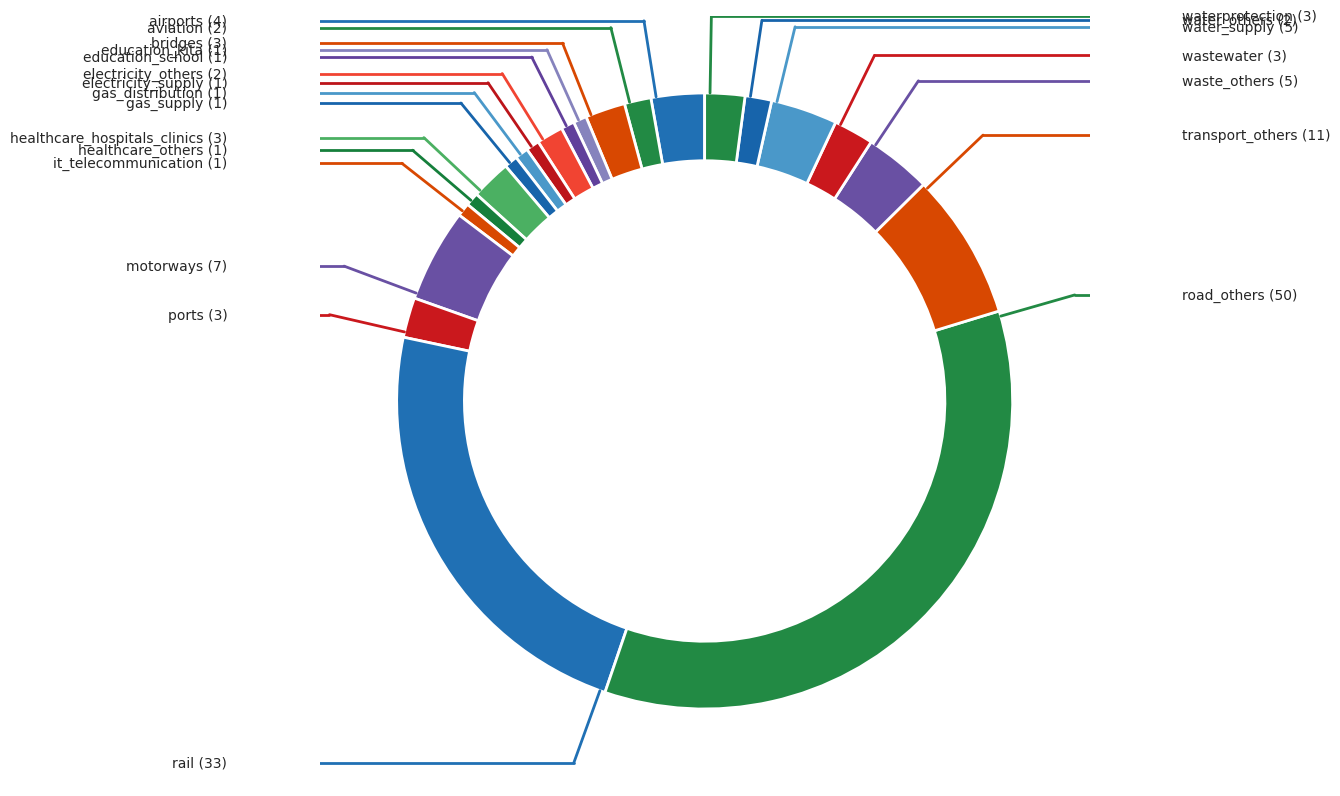

In [ ]:
# * histogram plot showing which are most common in the prediction set

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# --- Load your CSV ---
# Example CSV should have columns: category, value

# df_pred_plot = df_pred.groupby(["infrastructure_sector"])["infrastructure_group"].count().reset_index(name="infrastructure_group").sort_values(["infrastructure_group"], ascending=True)
# # df_pred[df_pred["infrastructure_group"].sort_values(ascending=False)]
# labels = df_pred_plot["infrastructure_group"].value_counts().index.tolist()  # get category labels in order of frequency
# sizes = df_pred_plot["infrastructure_group"].values
# groups = df_pred_plot["infrastructure_sector"]

df_plot = df_pred.copy()
# --- Aggregate data correctly ---
df_plot = (
    df_plot
    .groupby(["infrastructure_sector", "infrastructure_group"])
    .size()
    .reset_index(name="count")
)

# Sort by group then value (important for visual grouping)
df_plot = df_plot.sort_values(
    ["infrastructure_sector", "count"],
    ascending=[True, False]
)

labels = df_plot["infrastructure_group"]
sizes = df_plot["count"]
groups = df_plot["infrastructure_sector"]

# --- Seaborn style ---
sns.set_theme(style="white", context="talk")

# --- Grouped color palettes (soft infographic style) ---
unique_groups = groups.unique()
base_palettes = ["Blues", "Greens", "Oranges", "Purples", "Reds"]

group_palettes = {}
for i, group in enumerate(unique_groups):
    n = (groups == group).sum()
    # Use lighter range for infographic feel
    palette = sns.color_palette(base_palettes[i % len(base_palettes)], n + 2)[2:]
    group_palettes[group] = palette

# Assign colors in order
colors = []
counters = {g: 0 for g in unique_groups}

for g in groups:
    colors.append(group_palettes[g][counters[g]])
    counters[g] += 1

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 10))

wedges, _ = ax.pie(
    sizes,
    colors=colors,
    startangle=90,
    wedgeprops=dict(
        width=0.22,           # thinner ring (closer to infographic)
        edgecolor="white",    # creates separation between segments
        linewidth=2
    )
)

# --- Leader lines at END of each segment ---
for i, wedge in enumerate(wedges):
    # Use END of wedge instead of center
    angle = wedge.theta2 -1
    rad = np.deg2rad(angle)

    x, y = np.cos(rad), np.sin(rad)

    # Start exactly at outer edge
    r_outer = 1.0
    r_mid = 1.25

    start = (x * r_outer, y * r_outer)
    mid = (x * r_mid, y * r_mid)

    # Push labels further out for clarity
    end_x = 1.55 if x > 0 else -1.55
    end_y = mid[1]

    align = "left" if x > 0 else "right"

    # Draw leader lines (now anchored at segment END)
    ax.plot([start[0], mid[0]], [start[1], mid[1]],
            color=colors[i], lw=2)
    ax.plot([mid[0], end_x], [mid[1], end_y],
            color=colors[i], lw=2)

    # Label
    ax.text(
        end_x,
        end_y,
        f"{labels.iloc[i]} ({sizes.iloc[i]})",
        ha=align,
        va="center",
        fontsize=10
    )

In [ ]:
# * histogram plot showing which are most common in the prediction set

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# --- Load your CSV ---
# Example CSV should have columns: category, value

df_pred_plot = df_pred.groupby(["infrastructure_sector"])["infrastructure_group"].count().reset_index(name="infrastructure_group").sort_values(["infrastructure_group"], ascending=True)
# df_pred[df_pred["infrastructure_group"].sort_values(ascending=False)]
labels = df_pred_plot["infrastructure_group"].value_counts().index.tolist()  # get category labels in order of frequency
sizes = df_pred_plot["infrastructure_group"].values
groups = df_pred_plot["infrastructure_sector"]


# --- Seaborn styling ---
sns.set_theme(style="white")

# --- Create color mapping per group ---
unique_groups = groups.unique()
group_palettes = {}

# Assign a base palette per group
base_palettes = ["Blues", "Greens", "Reds", "Purples", "Oranges"]

for i, group in enumerate(unique_groups):
    count = sum(groups == group)
    palette = sns.color_palette(base_palettes[i % len(base_palettes)], count)
    group_palettes[group] = palette

# Flatten colors in correct order
colors = []
group_counters = {g: 0 for g in unique_groups}

for g in groups:
    colors.append(group_palettes[g][group_counters[g]])
    group_counters[g] += 1

# --- Create donut chart ---
fig, ax = plt.subplots(figsize=(8, 8))

wedges, _ = ax.pie(
    sizes,
    colors=colors,
    startangle=90,
    wedgeprops=dict(width=0.25)  # thin ring
)

# --- Leader lines ---
for i, wedge in enumerate(wedges):
    angle = (wedge.theta2 + wedge.theta1) / 2
    angle_rad = np.deg2rad(angle)

    x = np.cos(angle_rad)
    y = np.sin(angle_rad)

    start_x, start_y = x * 1.0, y * 1.0
    mid_x, mid_y = x * 1.2, y * 1.2
    end_x = 1.4 if x > 0 else -1.4
    end_y = mid_y

    align = "left" if x > 0 else "right"

    # Colored leader lines
    ax.plot([start_x, mid_x], [start_y, mid_y], color=colors[i], lw=1.5)
    ax.plot([mid_x, end_x], [mid_y, end_y], color=colors[i], lw=1.5)

    # Label includes group (optional)
    ax.text(
        end_x,
        end_y,
        "sss", #f"{labels[i]} ({sizes[i]})",
        ha=align,
        va="center",
        fontsize=10
    )

# --- Final styling ---
ax.set(aspect="equal")
plt.title("Donut Chart with Grouped Color Shades", fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:

# --- Seaborn styling ---
sns.set_theme(style="white")

# --- Create color mapping per group ---
unique_groups = groups.unique()
group_palettes = {}

# Assign a base palette per group
base_palettes = ["Blues", "Greens", "Reds", "Purples", "Oranges"]

for i, group in enumerate(unique_groups):
    count = sum(groups == group)
    palette = sns.color_palette(base_palettes[i % len(base_palettes)], count)
    group_palettes[group] = palette

# Flatten colors in correct order
colors = []
group_counters = {g: 0 for g in unique_groups}

for g in groups:
    colors.append(group_palettes[g][group_counters[g]])
    group_counters[g] += 1

# --- Create donut chart ---
fig, ax = plt.subplots(figsize=(8, 8))

wedges, _ = ax.pie(
    sizes,
    colors=colors,
    startangle=90,
    wedgeprops=dict(width=0.25)  # thin ring
)

# --- Leader lines ---
for i, wedge in enumerate(wedges):
    angle = (wedge.theta2 + wedge.theta1) / 2
    angle_rad = np.deg2rad(angle)

    x = np.cos(angle_rad)
    y = np.sin(angle_rad)

    start_x, start_y = x * 1.0, y * 1.0
    mid_x, mid_y = x * 1.2, y * 1.2
    end_x = 1.4 if x > 0 else -1.4
    end_y = mid_y

    align = "left" if x > 0 else "right"

    # Colored leader lines
    ax.plot([start_x, mid_x], [start_y, mid_y], color=colors[i], lw=1.5)
    ax.plot([mid_x, end_x], [mid_y, end_y], color=colors[i], lw=1.5)

    # Label includes group (optional)
    ax.text(
        end_x,
        end_y,
        f"{labels[i]} ({sizes[i]})",
        ha=align,
        va="center",
        fontsize=10
    )

# --- Final styling ---
ax.set(aspect="equal")
plt.title("Donut Chart with Grouped Color Shades", fontsize=14)

plt.tight_layout()
plt.show()


In [ ]:

# # --- Seaborn styling ---
# sns.set_theme(style="white")
# colors = sns.color_palette("tab10", len(df_pred))

# # --- Create donut chart ---
# fig, ax = plt.subplots(figsize=(8, 8))

# wedges, _ = ax.pie(
#     sizes,
#     colors=colors,
#     startangle=90,
#     wedgeprops=dict(width=0.25)  # thinner ring
# )

# # --- Add colored leader lines and labels ---
# for i, wedge in enumerate(wedges):
#     angle = (wedge.theta2 + wedge.theta1) / 2
#     angle_rad = np.deg2rad(angle)

#     # Outer edge of donut (exact end of subsection)
#     x = np.cos(angle_rad)
#     y = np.sin(angle_rad)

#     # Start at outer edge of donut
#     start_x = x * 1.0
#     start_y = y * 1.0

#     # Extend outward
#     mid_x = x * 1.2
#     mid_y = y * 1.2

#     # Horizontal extension for label alignment
#     end_x = 1.4 if x > 0 else -1.4
#     end_y = mid_y

#     align = "left" if x > 0 else "right"

#     # Draw two-segment leader line (radial + horizontal)
#     ax.plot([start_x, mid_x], [start_y, mid_y], color=colors[i], lw=1.5)
#     ax.plot([mid_x, end_x], [mid_y, end_y], color=colors[i], lw=1.5)

#     # Add label
#     ax.text(
#         end_x,
#         end_y,
#         f"{labels[i]} ({sizes[i]})",
#         ha=align,
#         va="center",
#         fontsize=10
#     )

# # --- Final styling ---
# ax.set(aspect="equal")
# plt.title("Improved Donut Chart with Colored Leader Lines", fontsize=14)

# plt.tight_layout()
# plt.show()

### Valid DS / PRed DS load

In [9]:


# print("Use only citations which are in both")

# df_valid = df_valid_org[df_valid_org["publication_id"].isin(df_pred.citation_id.unique())]
# # df_valid_org[df_valid_org["publication_id"].isin(citation_list)]
# print("Valid citations:")
# print(set(sorted(df_valid.publication_id)))

# # df = df_valid
# df_plot = df_valid


In [10]:
import pandas as pd

# df_pred = pd.DataFrame()
# for i, file in enumerate(glob.glob(os.path.join("../interim_results_debug", f'llm_geollm_chain_{step}_*.csv'))):
#     try:
#         df_pred = pd.concat([df_pred, pd.read_csv(file)], ignore_index=True)
#     except:
#         print("Not added: ", i, file)
#         pass

# # df_pred.citation_id.unique()


print("Use only citations which are in both")

# Keep only entries which are also in preidction set
# df_pred = df_pred[df_pred["citation_id"].isin(df_valid.publication_id.unique())]
print(f"Predicted citations [{len(set(sorted(df_pred.citation_id)))} docs]:")
print(set(sorted(df_pred.citation_id)))


df_plot = df_pred


Use only citations which are in both
Predicted citations [68 docs]:
{'Karakatsani 2023', 'Mohr 2022', 'Cavaleri 2019', 'Koks 2022', 'The Maritime Executive 2024', "Lloyd's List 2024", 'Vinke 2024', 'AEMET 2024', 'Tempest 2019', 'Wildhagen 2013', 'Handelsblatt 2023', 'The Vibes 2022', 'Zeit 2026', 'Deidda 2025', 'Brown 2010', 'Manhold 2021', 'Lavenir_(b) 2021', 'Pescaroli 2017', 'Reuters 2023', 'The Guardian 2015', 'European Investment Bank 2025', 'Kettle 2020', 'Ferlita 2023', 'Kadir 2014', 'Diakakis 2020', 'Keller 2014', 'Papaioannou 2026', 'Skoulding 2023', 'Fink 2004', 'Koks 2019', 'Prack 2020', 'Containerlift 2024', 'AFP 2022', 'Clapson 2021', 'Nieuwsblad 2021', 'McGregor 2007', 'BBC 2020', 'Korzilius 2021', 'Fekete 2025', 'Met office 2014', 'IPCC 2018', 'Chamra 2006', 'Nour 2011', 'EFE 2024', 'Stahl 2016', 'Eurelectric 2006', 'ABC 2024', 'Khazai 2013', 'The Guardian 2018', 'Grieshaber 2026', 'UNEP 2013', 'Gilbody Dickerson 2024', 'Fastrich 2021', 'Treanor 2015', 'Fink 2009', 'Maio

In [11]:
# handle concatenated entries
print(df_plot.economic_impact_origin.value_counts())
df_plot = pp.split_text_into_multiple_rows(df_plot, "economic_impact_origin", ", ")
df_plot = pp.split_text_into_multiple_rows(df_plot, "economic_impact_type", ", ")
df_plot = pp.split_text_into_multiple_rows(df_plot, "societal_impact_origin", ", ")
df_plot = pp.split_text_into_multiple_rows(df_plot, "societal_impact_type", ", ")
df_plot = pp.split_text_into_multiple_rows(df_plot, "secondary_infrastructure_asset", ", ")
print(df_plot.economic_impact_origin.value_counts())
## remove duplicates 
print(f"\nDropping {df_plot.duplicated().sum()} duplicates in postprocessed prediction data")
df_plot = df_plot.drop_duplicates()
print(f"Dropping { df_plot.shape[0] - df_plot[df_plot.duplicated() == False].shape[0]} duplicates in pred data")
df_plot = df_plot[df_plot.duplicated() == False]




economic_impact_origin
downstream_economic_consequence                                                                                                       87
repair_recovery_cost                                                                                                                  40
other_costs_or_losses                                                                                                                 10
repair_recovery_cost, other_costs_or_losses, downstream_economic_consequence                                                           2
repair_recovery_cost, other_costs_or_losses                                                                                            2
downstream_economic_consequence, downstream_economic_consequence                                                                       2
other_costs_or_losses, downstream_economic_consequence                                                                                 1
downstream_economi

In [12]:

# df = df_pred
# df = pp.split_ci_entities(df, columns=["infrastructure_type"])
# df["secondary_infrastructure_group"] = None
# # redo CI group creation as "split_ci_entities()" just splitted concatinated entries ("road and rail network")
# # # if not "infrastructure_group" in df.columns or df["infrastructure_group"].isna().any():
# df = pp.group_ci_types(df, "infrastructure_type", "infrastructure_group", ci_patterns)
# df = pp.group_ci_types(df, "secondary_infrastructure_asset", "secondary_infrastructure_group", ci_patterns)

# # keep only records which are actually about CI (e.g., not theatre, stadion ..)
# df.dropna(subset=["infrastructure_group"], inplace=True)

In [13]:

# df_plot = df.copy(deep=True)

## Prep - create sector and subsector ("group") columns with nice labels 
# print(df_plot["infrastructure_group"].unique())
# df_plot["infrastructure_group"] = df_plot["infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# # print(df_plot["infrastructure_group"].unique())
# df_plot["infrastructure_sector"] = df_plot["infrastructure_group"].str.split(" - ").str[0]
# df_plot["infrastructure_group"] = df_plot["infrastructure_group"].str.split(" - ").str[1]


# # group into sectors
# df_plot["infrastructure_group4sector"] = df_plot["infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# # # print(df_plot["secondary_infrastructure_group"].unique())
# df_plot["infrastructure_sector"] = df_plot["infrastructure_group4sector"].str.split(" - ").str[0]

# df_plot["secondary_infrastructure_sector"] = df_plot["secondary_infrastructure_group"].map(cigroup_labels)  # non-matched entries are set to NAN
# # # print(df_plot["secondary_infrastructure_group"].unique())
# df_plot["secondary_infrastructure_sector"] = df_plot["secondary_infrastructure_sector"].str.split(" - ").str[0]





In [14]:
# df_plot[df_plot['secondary_infrastructure_asset'] == df_plot["infrastructure_type"]]
#except:
  #  df_plot['secondary_infrastructure_asset'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_asset'] == row["ci1_type"] else row['secondary_infrastructure_asset'], axis=1)
 #   
#df_plot['secondary_infrastructure_group'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_group'] == row["infrastructure_group"] else row['secondary_infrastructure_group'], axis=1)


In [15]:

## remove secondary_infrastructure_asset and secondary_infrastructure_asset-group entry when it is identical to  infrastructure_group
try:
    df_plot['secondary_infrastructure_asset'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_asset'] == row["infrastructure_type"] else row['secondary_infrastructure_asset'], axis=1)
except:
    df_plot['secondary_infrastructure_asset'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_asset'] == row["ci1_type"] else row['secondary_infrastructure_asset'], axis=1)
df_plot['secondary_infrastructure_group'] = df_plot.apply(lambda row: None if row['secondary_infrastructure_group'] == row["infrastructure_group"] else row['secondary_infrastructure_group'], axis=1)
    


## remove economic_impact_origin entry when it economic_impact_type is NAN or None
print(df_plot.economic_impact_origin.value_counts())
df_plot['economic_impact_origin'] = df_plot.apply(lambda row: None if  (row["economic_impact_type"] in ["None", None, "none", np.nan, "NAN"] ) else row['economic_impact_origin'], axis=1)
print(df_plot.economic_impact_origin.value_counts())

print(df_plot.societal_impact_origin.value_counts())
df_plot['societal_impact_origin'] = df_plot.apply(lambda row: None if  (row["societal_impact_type"] in ["None", None, "none", np.nan, "NAN"] ) else row['societal_impact_origin'], axis=1)
print(df_plot.societal_impact_origin.value_counts())


df_plot[
    [
    # "infrastructure_type", "location", "damage", 
    "infrastructure_group", #"infrastructure_sector", 
    "economic_impact_type", "societal_impact_type", "secondary_infrastructure_asset", "secondary_infrastructure_group", "secondary_infrastructure_sector"]
][100:]

economic_impact_origin
downstream_economic_consequence    115
repair_recovery_cost                60
other_costs_or_losses               22
Name: count, dtype: int64
economic_impact_origin
downstream_economic_consequence    114
repair_recovery_cost                60
other_costs_or_losses               22
Name: count, dtype: int64
societal_impact_origin
loss_of_critical_service_or_inaccessibility    80
disruption_of_mobility                         77
other_affected_population                      59
evacuation_or_displacement                     23
Name: count, dtype: int64
societal_impact_origin
loss_of_critical_service_or_inaccessibility    73
disruption_of_mobility                         60
other_affected_population                      59
evacuation_or_displacement                     23
Name: count, dtype: int64


,infrastructure_group,economic_impact_type,societal_impact_type,secondary_infrastructure_asset,secondary_infrastructure_group,secondary_infrastructure_sector
100,electricity_supply,NaN,NaN,NaN,NaN,NaN
101,electricity_supply,NaN,NaN,NaN,NaN,NaN
102,electricity_supply,prices for electricity increased,NaN,NaN,NaN,NaN
103,NaN,NaN,NaN,NaN,NaN,NaN
104,healthcare_clinics,NaN,evacuated residents and tourists,NaN,NaN,NaN
...,...,...,...,...,...,...
1195,vessels,supply chain disruption,NaN,NaN,NaN,NaN
1196,transport_general,NaN,NaN,NaN,NaN,NaN
1197,ports,transport disruption,NaN,NaN,NaN,NaN
1198,vessels,NaN,NaN,NaN,NaN,NaN


In [16]:
# df_plot.societal_impact_type.value_counts()


df_plot[
    [
    # "infrastructure_type", "location", "damage", 
    "infrastructure_group", #"infrastructure_sector", 
    "economic_impact_type", "societal_impact_type", "secondary_infrastructure_asset", "secondary_infrastructure_group", "secondary_infrastructure_sector"]
][0:25]

df_plot[~df_plot["secondary_infrastructure_group"].isna()] #and ~df_plot["infrastructure_type"].isna()]#[["economic_impact_origin", "economic_impact_type", "economic_impact_amount", "chunk_text"]]

,is_infrastructure_case,infrastructure_type,infrastructure_amount,location,damage,economic_impact_type,economic_impact_origin,economic_impact_amount,economic_impact_unit,societal_impact_origin,...,location_orig,judge_verdict,judge_adapted_fields,judge_reason,judge_evidence,judge_evidence_in_text,judge_adaptation_in_text,infrastructure_sector,secondary_infrastructure_group,secondary_infrastructure_sector
15,True,nuclear power plants,NaN,NaN,service_loss,NaN,NaN,NaN,NaN,NaN,...,NaN,correct,NaN,The shutdown of nuclear power plants is a service_loss that subsequently impacts the power supply.,Impacts of power supply may also be a result of the shutdown of nuclear power plants because cooling water temperatures become too high,True,NaN,Energy,electricity_supply,Energy
36,True,Valencia Airport,NaN,Valencia Airport,disruption,NaN,NaN,NaN,NaN,disruption_of_mobility,...,"Valencia Airport, eastern Spain",adapted,"{""damage"": {""old"": ""service_loss"", ""new"": ""disruption""}, ""economic_impact_origin"": {""old"": ""downstream_economic_consequence, downstream_economic_consequence"", ""new"": null}, ""economic_impact_type"": {""old"": ""flight cancellations and diversions, business interruption"", ""new"": null}, ""societal_impact_origin"": {""old"": ""disruption_of_mobility, disruption_of_mobility"", ""new"": ""disruption_of_mobility""}, ""societal_impact_type"": {""old"": ""passengers unable to travel, passengers unable to travel"", ""new"": ""flights diverted and cancellations""}, ""societal_impact_amount"": {""old"": ""10, 28"", ""new"": null}, ""societal_impact_unit"": {""old"": ""flights diverted, flights cancelled"", ""new"": null}}",Damage for transportation infrastructure (airport) should be 'disruption' (halted/closed). Economic impacts are not explicitly stated as costs or losses. Societal impact amount/unit were incorrectly filled with flight counts; flight diversions/cancellations are the type of mobility disruption. Secondary infrastructure 'flights' is not an asset.,"Flights were briefly halted at Valencia Airport in eastern Spain yesterday after lightning and heavy flooding struck the runway following hours of torrential rain, airport officials said. ... In the end, 10 flights were diverted to other airports and there were 28 cancellations",False,False,Transportation,aviation,Transportation
43,True,Prague metro system,approximately one third,Prague,inundation,NaN,NaN,NaN,NaN,loss_of_critical_service_or_inaccessibility,...,Prague,adapted,"{""economic_impact_origin"": {""old"": ""downstream_economic_consequence, downstream_economic_consequence"", ""new"": null}, ""economic_impact_type"": {""old"": ""transportation disruption, business interruption"", ""new"": null}, ""secondary_infrastructure_asset"": {""old"": ""public transport system (metro)"", ""new"": ""the public transport system""}}",Adapted infrastructure_type and secondary_infrastructure_asset to match NER/TEXT. Removed economic impacts as they are not explicitly stated in the text (only service loss is mentioned).,"Some districts of the capital city, as well as approximately one third of the Prague metro system was flooded. This caused the artery of the public transport system - the metro - to be out of service for a long time.",True,True,Transportation,transport_general,Transportation
45,True,the flooded tunnels,NaN,Prague,inundation,NaN,NaN,NaN,NaN,NaN,...,Prague,adapted,"{""infrastructure_type"": {""old"": ""tunnels"", ""new"": ""the flooded tunnels""}, ""secondary_infrastructure_asset"": {""old"": ""public transport system (metro)"", ""new"": ""the public transport system""}}",Adapted infrastructure_type to match NER and secondary_infrastructure_asset to match NER.,In the flooded tunnels and metro stations there were approximately 1.2 million cubic metres of water.,True,True,Transportation,transport_general,Transportation
46,True,metro stations,NaN,Prague,inundation,NaN,NaN,NaN,NaN,NaN,...,Prague,adapted,"{""secondary_infrastructure_asset"": {""old"": ""publ

In [17]:

# df_plot['economic_impact_type'] = df_plot['economic_impact_type'].map({"NAN":False, None:False})
# df_plot.economic_impact_type = df_plot.economic_impact_type.astype(bool) # all str --> True
# df_plot['economic_impact_type'] = df_plot['economic_impact_type'].map({True:"Economic impacts"})
# # df_plot['economic_impacts'] = df_plot['economic_impacts'].map({np.nan:"No cascading impact"})

# df_plot['societal_impact_type'] = df_plot['societal_impact_type'].map({"NAN":False, None:False})
# df_plot.societal_impact_type = df_plot.societal_impact_type.astype(bool)
# df_plot['societal_impact_type'] = df_plot['societal_impact_type'].map({True:"Societal impacts"})

# df_plot['infrastructure_impacts_group'] = df_plot['infrastructure_impacts_group'].map({"NAN":False, None:False})

# df_plot['societal_impacts'] = df_plot['societal_impacts'].map({np.nan:"No cascading impact"})

df_plot[["economic_impact_type", "societal_impact_type", 'infrastructure_impacts_group']] = df_plot[["economic_impact_type", "societal_impact_type", 'secondary_infrastructure_group']].replace(np.nan, "No cascading impact")


print(df_plot.economic_impact_type.value_counts())
print(df_plot.societal_impact_type.value_counts())
print(df_plot.secondary_infrastructure_group.value_counts())

df_plot[
    [    # "infrastructure_type", "location", "damage", 
    "infrastructure_group", "infrastructure_sector", 
    "economic_impact_type", "societal_impact_type", "secondary_infrastructure_asset", "secondary_infrastructure_group",  "secondary_infrastructure_sector"]
][:20]


economic_impact_type
No cascading impact                987
repair cost                         22
business interruption               10
economic loss                        9
transport disruption                 7
                                  ... 
macroeconomic impacts                1
disruption to supply chains          1
business disruption                  1
systemic disruption                  1
financial losses for businesses      1
Name: count, Length: 97, dtype: int64
societal_impact_type
No cascading impact                                   981
affected people                                        12
disrupted mobility                                      9
affected households                                     8
access areas were promptly closed to the travelers      8
                                                     ... 
people impacted by outage                               1
Water supply shortages                                  1
inconvenience for passenger

,infrastructure_group,infrastructure_sector,economic_impact_type,societal_impact_type,secondary_infrastructure_asset,secondary_infrastructure_group,secondary_infrastructure_sector
0,roads,Transportation,No cascading impact,No cascading impact,NaN,NaN,NaN
1,motorways,Transportation,economic losses,No cascading impact,NaN,NaN,NaN
2,roads,Transportation,No cascading impact,No cascading impact,NaN,NaN,NaN
3,motorways,Transportation,No cascading impact,No cascading impact,NaN,NaN,NaN
4,motorways,Transportation,economic losses,No cascading impact,NaN,NaN,NaN
5,roads,Transportation,repair cost,No cascading impact,NaN,NaN,NaN
6,motorways,Transportation,repair cost,No cascading impact,NaN,NaN,NaN
7,roads,Transportation,repair cost,No cascading impact,NaN,NaN,NaN
8,electricity_supply,Energy,No cascading impact,No cascading impact,NaN,NaN,NaN
9,electricity_supply,Energy,No cascading impact,No cascading impact,NaN,NaN,NaN


In [18]:
# df_plot.secondary_infrastructure_group.value_counts()

## Sankey plot - CI cascades

In [62]:
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt


# ============================================================
# Base palettes
# ============================================================

base_palettes = {

    "Transportation": "bone_r",
    "Energy": "Oranges",
    "Water": "Blues",
    "Structural Protection Measures": "BrBG_r",
    "Waste": "copper_r",
    "Education": "PuRd",
    "Health": "PuRd",
    "Other": "Greys_r",
    "IT / Communication": "Purples_r",
}


# ============================================================
# Helper: convert matplotlib colour to Plotly RGBA
# ============================================================

def cmap_to_rgba(
    cmap_name,
    position=0.60,
    alpha=1.0
):
    cmap = plt.colormaps[cmap_name]
    rgba = cmap(position)

    return (
        f"rgba("
        f"{int(rgba[0] * 255)},"
        f"{int(rgba[1] * 255)},"
        f"{int(rgba[2] * 255)},"
        f"{alpha}"
        f")"
    )


# ============================================================
# Fixed colour per sector
# ============================================================

sector_colors = {
    sector: cmap_to_rgba(
        palette,
        position=0.60,
        alpha=1.0
    )
    for sector, palette in base_palettes.items()
}


# ============================================================
# Group -> sector mapping
# ============================================================

def create_group_sector_mapping(
    df,
    group_col,
    sector_col
):

    # If the columns don't exist, return an empty mapping
    if group_col not in df.columns or sector_col not in df.columns:
        return {}

    temp = (
        df[[group_col, sector_col]]
        .dropna(subset=[group_col, sector_col])
        .copy()
    )

    temp[group_col] = (
        temp[group_col]
        .astype(str)
        .str.strip()
    )

    temp[sector_col] = (
        temp[sector_col]
        .astype(str)
        .str.strip()
    )

    temp = temp[
        (temp[group_col] != "") &
        (temp[sector_col] != "")
    ]

    mapping = (
        temp
        .drop_duplicates(subset=[group_col])
        .set_index(group_col)[sector_col]
        .to_dict()
    )

    return mapping


# ============================================================
# Sankey function
# ============================================================

NO_CASCADE = "No cascading impact"

# values treated as "no impact" in the impact columns
EMPTY_VALUES = {"", "nan", "none", "null", "n/a"}

# label of the "No cascading impact" node per impact group
NO_CASCADE_LABELS = {
    "Economic": "No cascading impact (economic)",
    "Societal": "No cascading impact (societal)",
    "Infrastructure": "No cascading impact (CI)",
}

# readable labels for the impact categories on the right side
PRETTY_LABELS = {
    "repair_recovery_cost": "Repair & recovery costs",
    "downstream_economic_consequence": "Downstream economic consequences",
    "other_costs_or_losses": "Other costs or losses",
    "evacuation_or_displacement": "Evacuation or displacement",
    "loss_of_critical_service_or_inaccessibility": "Loss of critical services or inaccessibility",
    "disruption_of_mobility": "Disruption of mobility",
    "other_affected_population": "Other affected population",
}


def pretty_label(label: str) -> str:
    """Readable label: from PRETTY_LABELS, else '_' -> ' ' and first letter upper case (e.g. 'water_supply' -> 'Water supply')."""
    if label in PRETTY_LABELS:
        return PRETTY_LABELS[label]
    label = label.replace("_", " ").strip()
    return label[:1].upper() + label[1:]


# colour of the "No cascading impact" node per impact group
NO_CASCADE_COLORS = {
    "Economic": "rgba(31, 119, 180, 1)",     # blue, as the economic impacts
    "Societal": "rgba(231, 84, 128, 1)",     # pink, as the societal impacts
    "Infrastructure": "rgba(150,150,150,1)", # grey
}

def create_impact_sankey(
    df: pd.DataFrame,
    asset_col: str | None = None,
    impact_cols: dict | None = None,
    link_alpha: float = 0.30,
    ci_target_level: str = "group",
):
    """ci_target_level: level of the infrastructure on both sides of the plot:
    "group":  left infrastructure_group, right secondary_infrastructure_group
              (fallback secondary_infrastructure_asset)
    "sector": left infrastructure_sector, right secondary_infrastructure_sector
    asset_col overrides the left column, impact_cols the right columns."""

    df = df.copy()

    if ci_target_level not in ("group", "sector"):
        raise ValueError(
            f"ci_target_level must be 'group' or 'sector', not '{ci_target_level}'."
        )

    # left side: infrastructure groups or sectors
    if asset_col is None:
        asset_col = (
            "infrastructure_sector"
            if ci_target_level == "sector"
            else "infrastructure_group"
        )

    # ========================================================
    # Identify impact columns
    # ========================================================

    if impact_cols is None:

        if ci_target_level == "sector":

            if "secondary_infrastructure_sector" not in df.columns:
                raise ValueError(
                    "Could not find 'secondary_infrastructure_sector' "
                    "for ci_target_level='sector'."
                )

            infrastructure_col = "secondary_infrastructure_sector"

        elif "secondary_infrastructure_group" in df.columns:
            infrastructure_col = "secondary_infrastructure_group"

        elif "secondary_infrastructure_asset" in df.columns:
            infrastructure_col = "secondary_infrastructure_asset"

        else:
            raise ValueError(
                "Could not find 'secondary_infrastructure_group' "
                "or 'secondary_infrastructure_asset'."
            )

        impact_cols = {
            # "Economic": "economic_impact_type",
            "Economic": "economic_impact_origin",
            # "Societal": "societal_impact_type",
            "Societal": "societal_impact_origin",
            "Infrastructure": infrastructure_col,
        }

    # ========================================================
    # Group -> sector mappings
    # ========================================================

    source_group_sector = create_group_sector_mapping(
        df,
        "infrastructure_group",
        "infrastructure_sector"
    )

    target_group_sector = create_group_sector_mapping(
        df,
        "secondary_infrastructure_group",
        "secondary_infrastructure_sector"
    )

    # sector level: the left nodes already are sectors (sector -> itself)
    if ci_target_level == "sector":
        source_group_sector = {
            x: x
            for x in df[asset_col].dropna().astype(str).str.strip()
            if x
        }

    # ========================================================
    # Create source-target relationships
    # ========================================================

    links = []

    for _, row in df.iterrows():

        asset = row.get(asset_col)

        if pd.isna(asset):
            continue

        asset = str(asset).strip()

        if not asset:
            continue

        # ----------------------------------------------------
        # Process the three impact columns separately:
        # NaN / None / empty / "No cascading impact" of a group
        # -> ONE "No cascading impact" node of THIS group
        # ----------------------------------------------------

        for impact_type, col in impact_cols.items():

            value = row.get(col)

            if pd.isna(value) or str(value).strip().lower() in EMPTY_VALUES:
                impacts = []
            else:
                # Split semicolon-separated impacts
                impacts = [
                    x.strip()
                    for x in str(value).split(";")
                    if x.strip() and x.strip().lower() not in EMPTY_VALUES
                ]

            # Ignore "No cascading impact" placeholders, keep only real impacts
            impacts = [
                x for x in impacts
                if x.lower() != NO_CASCADE.lower()
            ]

            if not impacts:
                impacts = [NO_CASCADE]

            for impact in impacts:

                links.append({
                    "source": asset,
                    "target": impact,
                    "target_type": impact_type,
                    "value": 1,
                })

    links = pd.DataFrame(links)

    if links.empty:
        raise ValueError(
            "No source-target relationships were found."
        )

    # ========================================================
    # Aggregate identical source-target relationships
    # ========================================================

    links = (
        links
        .groupby(
            ["source", "target", "target_type"],
            as_index=False
        )["value"]
        .sum()
    )


    # ========================================================
    # ORDER SOURCE NODES BY SECTOR AND SIZE
    # ========================================================

    # Size of each infrastructure group
    # = total number of source -> target links
    source_sizes = (
        links
        .groupby("source")["value"]
        .sum()
        .reset_index(name="size")
    )

    # Add infrastructure sector
    source_sizes["sector"] = (
        source_sizes["source"]
        .map(source_group_sector)
        .fillna("Other")
    )

    # --------------------------------------------------------
    # Order sectors by their total size
    # --------------------------------------------------------

    sector_sizes = (
        source_sizes
        .groupby("sector")["size"]
        .sum()
        .sort_values(ascending=False)
    )

    ordered_sectors = sector_sizes.index.tolist()

    # --------------------------------------------------------
    # Order infrastructure groups within each sector by size
    # --------------------------------------------------------

    ordered_sources = []

    for sector in ordered_sectors:

        sector_sources = (
            source_sizes[
                source_sizes["sector"] == sector
            ]
            .sort_values(
                "size",
                ascending=False
            )
        )

        ordered_sources.extend(
            sector_sources["source"].tolist()
        )

    # --------------------------------------------------------
    # Create source node IDs in the desired order
    # --------------------------------------------------------

    source_nodes = [
        f"asset::{x}"
        for x in ordered_sources
    ]

    # ========================================================
    # Create target nodes
    # ========================================================

    # Order: grouped by impact type (economic, societal, cascaded CI),
    # the group's "No cascading impact" node at the end of its block
    type_order = list(impact_cols)

    target_nodes = sorted(
        {f"{row.target_type}::{row.target}" for row in links.itertuples()},
        key=lambda node: (
            type_order.index(node.split("::", 1)[0]),
            node.split("::", 1)[1] == NO_CASCADE,
            node,
        ),
    )

    # ========================================================
    # All nodes
    # ========================================================

    all_node_ids = source_nodes + target_nodes

    # ========================================================
    # Node labels
    # ========================================================

    # Number of cases per node, shown as "<label> [<number of cases>]"
    # left:  number of cases (rows) of the infrastructure group
    # right: number of cases linked to the impact
    source_case_counts = (
        df[asset_col]
        .dropna()
        .astype(str)
        .str.strip()
        .loc[lambda x: x != ""]
        .value_counts()
    )

    target_case_counts = (
        links
        .assign(node=links["target_type"] + "::" + links["target"])
        .groupby("node")["value"]
        .sum()
    )

    node_labels = []

    for node in all_node_ids:

        if node.startswith("asset::"):

            label = node.replace("asset::", "")

            n_cases = source_case_counts.get(label, 0)

        else:

            target_type, label = node.split("::", 1)

            n_cases = target_case_counts.get(node, 0)

            if label == NO_CASCADE:
                label = NO_CASCADE_LABELS.get(target_type, f"{NO_CASCADE} ({target_type})")
            else:
                label = pretty_label(label)

        # all labels bold
        node_labels.append(f"<b>{label} [{n_cases}]</b>")

    # ========================================================
    # Node sectors and colours
    # ========================================================

    node_sectors = []
    node_colors = []

    for node in all_node_ids:

        # ----------------------------------------------------
        # SOURCE infrastructure node
        # ----------------------------------------------------

        if node.startswith("asset::"):

            group = node.replace("asset::", "")

            sector = source_group_sector.get(
                group,
                "Other"
            )

            color = sector_colors.get(
                sector,
                "rgba(150,150,150,1)"
            )

        # ----------------------------------------------------
        # TARGET node
        # ----------------------------------------------------

        else:

            target_type, group = node.split("::", 1)

            # "No cascading impact" of one of the three groups
            if group == NO_CASCADE:

                sector = f"{NO_CASCADE} ({target_type})"

                color = NO_CASCADE_COLORS.get(target_type, "rgba(150,150,150,1)")

            elif target_type == "Infrastructure":

                # ci_target_level="sector": the node already is the sector
                if ci_target_level == "sector":
                    sector = group
                else:
                    sector = target_group_sector.get(
                        group,
                        "Other"
                    )

                color = sector_colors.get(
                    sector,
                    "rgba(150,150,150,1)"
                )

            elif target_type == "Economic":

                sector = "Economic"
                color = "rgba(31, 119, 180, 1)"   # blue
                # color = "rgba(220, 0, 0, 1)"    red

            elif target_type == "Societal":

                sector = "Societal"
                # color = "rgba(220, 0, 0, 1)" # red
                color = "rgba(231, 84, 128, 1)"   # pink

            else:

                sector = "Other"

                color = "rgba(150,150,150,1)"

        node_sectors.append(sector)
        node_colors.append(color)

    # ========================================================
    # Node -> Sankey index
    # ========================================================

    node_id_to_index = {
        node_id: i
        for i, node_id in enumerate(all_node_ids)
    }


    # ========================================================
    # EXPLICIT NODE POSITIONS
    # ========================================================

    node_x = []
    node_y = []

    # --------------------------------------------------------
    # LEFT SIDE
    # --------------------------------------------------------

    # Give each infrastructure sector its own block.
    # Larger sectors appear first.
    # Groups within each sector retain their size ordering.
    # --------------------------------------------------------

    n_sources = len(ordered_sources)

    # Small vertical gap between sectors
    sector_gap = 0.015

    # Total available vertical space
    available_height = 0.97

    # Number of sector gaps
    n_sector_gaps = max(len(ordered_sectors) - 1, 0)

    # Space remaining for nodes
    node_area = available_height - (
        n_sector_gaps * sector_gap
    )

    # Total source size
    total_source_size = source_sizes["size"].sum()

    source_y_positions = {}

    current_y = 0.01

    for sector in ordered_sectors:

        sector_data = (
            source_sizes[
                source_sizes["sector"] == sector
            ]
            .sort_values(
                "size",
                ascending=False
            )
        )

        sector_total = sector_data["size"].sum()

        # Vertical space proportional to sector size
        sector_height = (
            sector_total / total_source_size
        ) * node_area

        n_groups = len(sector_data)

        if n_groups == 1:

            spacing = sector_height / 2

        else:

            spacing = sector_height / n_groups

        for i, source in enumerate(
            sector_data["source"]
        ):

            source_y_positions[source] = (
                current_y
                + (i + 0.5) * spacing
            )

        current_y += sector_height
        current_y += sector_gap


    # Add source coordinates
    for source in ordered_sources:

        node_x.append(0.01)

        node_y.append(
            source_y_positions[source]
        )


    # --------------------------------------------------------
    # RIGHT SIDE
    # --------------------------------------------------------

    # Keep the existing target order, but explicitly position
    # the targets so that arrangement="fixed" can be used.
    # --------------------------------------------------------

    target_y_positions = {}

    n_targets = len(target_nodes)

    if n_targets == 1:

        target_y_positions[target_nodes[0]] = 0.5

    else:

        target_spacing = (
            0.96 / n_targets
        )

        for i, target in enumerate(target_nodes):

            target_y_positions[target] = (
                0.01
                + (i + 0.5) * target_spacing
            )


    # Add target coordinates
    for target in target_nodes:

        node_x.append(0.99)

        node_y.append(
            target_y_positions[target]
        )

    # ========================================================
    # Create Sankey links
    # ========================================================

    sankey_source = []
    sankey_target = []
    sankey_value = []
    sankey_link_colors = []
    sankey_source_sectors = []

    for row in links.itertuples():

        # ----------------------------------------------------
        # Source
        # ----------------------------------------------------

        source_id = f"asset::{row.source}"

        # ----------------------------------------------------
        # Target
        # ----------------------------------------------------

        target_id = (
            f"{row.target_type}::{row.target}"
        )

        # ----------------------------------------------------
        # Source sector
        # ----------------------------------------------------

        source_sector = source_group_sector.get(
            row.source,
            "Other"
        )

        # ----------------------------------------------------
        # Link inherits SOURCE sector colour
        # ----------------------------------------------------

        if source_sector in base_palettes:

            link_color = cmap_to_rgba(
                base_palettes[source_sector],
                position=0.60,
                alpha=link_alpha
            )

        else:

            link_color = (
                f"rgba(150,150,150,{link_alpha})"
            )

        sankey_source.append(
            node_id_to_index[source_id]
        )

        sankey_target.append(
            node_id_to_index[target_id]
        )

        sankey_value.append(row.value)

        sankey_link_colors.append(
            link_color
        )

        sankey_source_sectors.append(
            source_sector
        )

    # ========================================================
    # Create Sankey
    # ========================================================

    fig = go.Figure(
        go.Sankey(

            arrangement="snap",

            node=dict(
                label=node_labels,
                color=node_colors,

                pad=20,
                thickness=20,

                x=node_x,
                y=node_y,

                customdata=node_sectors,

                hovertemplate=(
                    "<b>%{label}</b>"
                    "<br>Sector: %{customdata}"
                    "<extra></extra>"
                ),
            ),

            link=dict(
                source=sankey_source,
                target=sankey_target,
                value=sankey_value,

                color=sankey_link_colors,

                customdata=sankey_source_sectors,

                hovertemplate=(
                    "%{source.label}"
                    " → "
                    "%{target.label}"
                    "<br>Cases: %{value}"
                    "<br>Source sector: %{customdata}"
                    "<extra></extra>"
                ),
            ),
        )
    )

    fig.update_layout(
        title="Infrastructure Assets and Cascading Impacts",
        font=dict(
            size=18
        ),
        width=900,
        height=1000,
    )

    return fig, links

In [63]:
# df_plot#.citation_id.value_counts()

In [64]:
# fig, sankey_links = create_impact_sankey(df_plot)
fig, sankey_links = create_impact_sankey(df_plot, ci_target_level="sector") # sectors

fig

In [60]:
tt = sankey_links[sankey_links["target"]!="Economic impacts"]
tt = tt[tt["target"]!="Societal impacts"]
tt[tt["target"]!="No cascading impact"]

,source,target,target_type,value
3,Aviation,Transportation (not further specified),Infrastructure,2
5,Bridges,Road network,Infrastructure,1
22,Highways / Motorways,Transportation (not further specified),Infrastructure,4
32,Rail network,Rail service,Infrastructure,1
39,Road network,Rail network,Infrastructure,2
40,Road network,Rail service,Infrastructure,1
42,Road network,Transportation (not further specified),Infrastructure,3
47,Shipping traffic,Transportation (not further specified),Infrastructure,6
48,Transportation (not further specified),Aviation,Infrastructure,4
51,Transportation (not further specified),Shipping traffic,Infrastructure,1


## reste sankey plot

In [158]:
# import pandas as pd
# import plotly.graph_objects as go
# import matplotlib.pyplot as plt


# # ============================================================
# # Base palettes
# # ============================================================

# base_palettes = {

#     "Transportation": "bone_r",
#     "Energy": "Oranges",
#     "Water": "Blues",
#     "Structural Protection Measures": "BrBG_r",
#     "Waste": "copper_r",
#     "Education": "PuRd",
#     "Health": "PuRd",
#     "Other": "Greys_r",
#     "IT / Communication": "Purples_r",
# }


# # ============================================================
# # Helper: convert matplotlib colour to Plotly RGBA
# # ============================================================

# def cmap_to_rgba(
#     cmap_name,
#     position=0.60,
#     alpha=1.0
# ):
#     cmap = plt.colormaps[cmap_name]
#     rgba = cmap(position)

#     return (
#         f"rgba("
#         f"{int(rgba[0] * 255)},"
#         f"{int(rgba[1] * 255)},"
#         f"{int(rgba[2] * 255)},"
#         f"{alpha}"
#         f")"
#     )


# # ============================================================
# # Fixed colour per sector
# # ============================================================

# sector_colors = {
#     sector: cmap_to_rgba(
#         palette,
#         position=0.60,
#         alpha=1.0
#     )
#     for sector, palette in base_palettes.items()
# }


# # ============================================================
# # Group -> sector mapping
# # ============================================================

# def create_group_sector_mapping(
#     df,
#     group_col,
#     sector_col
# ):

#     # If the columns don't exist, return an empty mapping
#     if group_col not in df.columns or sector_col not in df.columns:
#         return {}

#     temp = (
#         df[[group_col, sector_col]]
#         .dropna(subset=[group_col, sector_col])
#         .copy()
#     )

#     temp[group_col] = (
#         temp[group_col]
#         .astype(str)
#         .str.strip()
#     )

#     temp[sector_col] = (
#         temp[sector_col]
#         .astype(str)
#         .str.strip()
#     )

#     temp = temp[
#         (temp[group_col] != "") &
#         (temp[sector_col] != "")
#     ]

#     mapping = (
#         temp
#         .drop_duplicates(subset=[group_col])
#         .set_index(group_col)[sector_col]
#         .to_dict()
#     )

#     return mapping


# # ============================================================
# # Sankey function
# # ============================================================

# def create_impact_sankey(
#     df: pd.DataFrame,
#     asset_col: str = "infrastructure_group",
#     impact_cols: dict | None = None,
#     link_alpha: float = 0.30,
# ):

#     df = df.copy()

#     # ========================================================
#     # Identify impact columns
#     # ========================================================

#     if impact_cols is None:

#         if "secondary_infrastructure_group" in df.columns:
#             infrastructure_col = "secondary_infrastructure_group"

#         elif "secondary_infrastructure_asset" in df.columns:
#             infrastructure_col = "secondary_infrastructure_asset"

#         else:
#             raise ValueError(
#                 "Could not find 'secondary_infrastructure_group' "
#                 "or 'secondary_infrastructure_asset'."
#             )

#         impact_cols = {
#             # "Economic": "economic_impact_type",
#             "Economic": "economic_impact_origin",
#             # "Societal": "societal_impact_type",
#             "Societal": "societal_impact_origin",
#             "Infrastructure": infrastructure_col,
#         }

#     # ========================================================
#     # Group -> sector mappings
#     # ========================================================

#     source_group_sector = create_group_sector_mapping(
#         df,
#         "infrastructure_group",
#         "infrastructure_sector"
#     )

#     target_group_sector = create_group_sector_mapping(
#         df,
#         "secondary_infrastructure_group",
#         "secondary_infrastructure_sector"
#     )

#     # ========================================================
#     # Create source-target relationships
#     # ========================================================

#     links = []

#     for _, row in df.iterrows():

#         asset = row.get(asset_col)

#         if pd.isna(asset):
#             continue

#         asset = str(asset).strip()

#         if not asset:
#             continue

#         row_impacts = []

#         # ----------------------------------------------------
#         # Process the three impact columns
#         # ----------------------------------------------------

#         for impact_type, col in impact_cols.items():

#             value = row.get(col)

#             # Empty value
#             if pd.isna(value):
#                 continue

#             # Split semicolon-separated impacts
#             impacts = [
#                 x.strip()
#                 for x in str(value).split(";")
#                 if x.strip()
#             ]

#             for impact in impacts:
#                 row_impacts.append(
#                     (impact_type, impact)
#                 )

#         # ----------------------------------------------------
#         # Determine whether this row has actual impacts
#         # ----------------------------------------------------

#         actual_impacts = [
#             (impact_type, impact)
#             for impact_type, impact in row_impacts
#             if impact.lower() != "no cascading impact"
#         ]

#         explicit_no_cascade = any(
#             impact.lower() == "no cascading impact"
#             for _, impact in row_impacts
#         )

#         # ----------------------------------------------------
#         # Case 1:
#         # No actual impacts at all
#         #
#         # This includes:
#         #   - all NaN
#         #   - explicit "No cascading impact"
#         # ----------------------------------------------------

#         if not actual_impacts:

#             links.append({
#                 "source": asset,
#                 "target": "No cascading impact",
#                 "target_type": "NoCascade",
#                 "value": 1,
#             })

#         # ----------------------------------------------------
#         # Case 2:
#         # Actual impacts exist
#         #
#         # Ignore "No cascading impact" placeholders
#         # and only keep the real impacts.
#         # ----------------------------------------------------

#         else:

#             for impact_type, impact in actual_impacts:

#                 links.append({
#                     "source": asset,
#                     "target": impact,
#                     "target_type": impact_type,
#                     "value": 1,
#                 })

#     links = pd.DataFrame(links)

#     if links.empty:
#         raise ValueError(
#             "No source-target relationships were found."
#         )

#     # ========================================================
#     # Aggregate identical source-target relationships
#     # ========================================================

#     links = (
#         links
#         .groupby(
#             ["source", "target", "target_type"],
#             as_index=False
#         )["value"]
#         .sum()
#     )


#     # ========================================================
#     # ORDER SOURCE NODES BY SECTOR AND SIZE
#     # ========================================================

#     # Size of each infrastructure group
#     # = total number of source -> target links
#     source_sizes = (
#         links
#         .groupby("source")["value"]
#         .sum()
#         .reset_index(name="size")
#     )

#     # Add infrastructure sector
#     source_sizes["sector"] = (
#         source_sizes["source"]
#         .map(source_group_sector)
#         .fillna("Other")
#     )

#     # --------------------------------------------------------
#     # Order sectors by their total size
#     # --------------------------------------------------------

#     sector_sizes = (
#         source_sizes
#         .groupby("sector")["size"]
#         .sum()
#         .sort_values(ascending=False)
#     )

#     ordered_sectors = sector_sizes.index.tolist()

#     # --------------------------------------------------------
#     # Order infrastructure groups within each sector by size
#     # --------------------------------------------------------

#     ordered_sources = []

#     for sector in ordered_sectors:

#         sector_sources = (
#             source_sizes[
#                 source_sizes["sector"] == sector
#             ]
#             .sort_values(
#                 "size",
#                 ascending=False
#             )
#         )

#         ordered_sources.extend(
#             sector_sources["source"].tolist()
#         )

#     # --------------------------------------------------------
#     # Create source node IDs in the desired order
#     # --------------------------------------------------------

#     source_nodes = [
#         f"asset::{x}"
#         for x in ordered_sources
#     ]

#     # ========================================================
#     # Create target nodes
#     # ========================================================

#     target_nodes = []

#     for row in links.itertuples():

#         # IMPORTANT:
#         # NoCascade has ONE shared node
#         if row.target_type == "NoCascade":

#             target_id = "no_cascade::No cascading impact"

#         else:

#             target_id = (
#                 f"{row.target_type}::{row.target}"
#             )

#         if target_id not in target_nodes:
#             target_nodes.append(target_id)

#     # ========================================================
#     # All nodes
#     # ========================================================

#     all_node_ids = source_nodes + target_nodes

#     # ========================================================
#     # Node labels
#     # ========================================================

#     node_labels = []

#     for node in all_node_ids:

#         if node.startswith("asset::"):

#             label = node.replace("asset::", "")

#         elif node.startswith("no_cascade::"):

#             label = "No cascading impact"

#         else:

#             label = node.split("::", 1)[1]

#         node_labels.append(label)

#     # ========================================================
#     # Node sectors and colours
#     # ========================================================

#     node_sectors = []
#     node_colors = []

#     for node in all_node_ids:

#         # ----------------------------------------------------
#         # SOURCE infrastructure node
#         # ----------------------------------------------------

#         if node.startswith("asset::"):

#             group = node.replace("asset::", "")

#             sector = source_group_sector.get(
#                 group,
#                 "Other"
#             )

#             color = sector_colors.get(
#                 sector,
#                 "rgba(150,150,150,1)"
#             )

#         # ----------------------------------------------------
#         # No cascading impact
#         # ----------------------------------------------------

#         elif node.startswith("no_cascade::"):

#             sector = "No cascading impact"

#             color = "rgba(220, 0, 0, 1)"

#         # ----------------------------------------------------
#         # TARGET node
#         # ----------------------------------------------------

#         else:

#             target_type, group = node.split("::", 1)

#             if target_type == "Infrastructure":

#                 sector = target_group_sector.get(
#                     group,
#                     "Other"
#                 )

#                 color = sector_colors.get(
#                     sector,
#                     "rgba(150,150,150,1)"
#                 )

#             elif target_type == "Economic":

#                 sector = "Economic"

#                 color = "rgba(220, 0, 0, 1)"

#             elif target_type == "Societal":

#                 sector = "Societal"

#                 color = "rgba(220, 0, 0, 1)"

#             else:

#                 sector = "Other"

#                 color = "rgba(150,150,150,1)"

#         node_sectors.append(sector)
#         node_colors.append(color)

#     # ========================================================
#     # Node -> Sankey index
#     # ========================================================

#     node_id_to_index = {
#         node_id: i
#         for i, node_id in enumerate(all_node_ids)
#     }


#     # ========================================================
#     # EXPLICIT NODE POSITIONS
#     # ========================================================

#     node_x = []
#     node_y = []

#     # --------------------------------------------------------
#     # LEFT SIDE
#     # --------------------------------------------------------

#     # Give each infrastructure sector its own block.
#     # Larger sectors appear first.
#     # Groups within each sector retain their size ordering.
#     # --------------------------------------------------------

#     n_sources = len(ordered_sources)

#     # Small vertical gap between sectors
#     sector_gap = 0.015

#     # Total available vertical space
#     available_height = 0.97

#     # Number of sector gaps
#     n_sector_gaps = max(len(ordered_sectors) - 1, 0)

#     # Space remaining for nodes
#     node_area = available_height - (
#         n_sector_gaps * sector_gap
#     )

#     # Total source size
#     total_source_size = source_sizes["size"].sum()

#     source_y_positions = {}

#     current_y = 0.01

#     for sector in ordered_sectors:

#         sector_data = (
#             source_sizes[
#                 source_sizes["sector"] == sector
#             ]
#             .sort_values(
#                 "size",
#                 ascending=False
#             )
#         )

#         sector_total = sector_data["size"].sum()

#         # Vertical space proportional to sector size
#         sector_height = (
#             sector_total / total_source_size
#         ) * node_area

#         n_groups = len(sector_data)

#         if n_groups == 1:

#             spacing = sector_height / 2

#         else:

#             spacing = sector_height / n_groups

#         for i, source in enumerate(
#             sector_data["source"]
#         ):

#             source_y_positions[source] = (
#                 current_y
#                 + (i + 0.5) * spacing
#             )

#         current_y += sector_height
#         current_y += sector_gap


#     # Add source coordinates
#     for source in ordered_sources:

#         node_x.append(0.01)

#         node_y.append(
#             source_y_positions[source]
#         )


#     # --------------------------------------------------------
#     # RIGHT SIDE
#     # --------------------------------------------------------

#     # Keep the existing target order, but explicitly position
#     # the targets so that arrangement="fixed" can be used.
#     # --------------------------------------------------------

#     target_y_positions = {}

#     n_targets = len(target_nodes)

#     if n_targets == 1:

#         target_y_positions[target_nodes[0]] = 0.5

#     else:

#         target_spacing = (
#             0.96 / n_targets
#         )

#         for i, target in enumerate(target_nodes):

#             target_y_positions[target] = (
#                 0.01
#                 + (i + 0.5) * target_spacing
#             )


#     # Add target coordinates
#     for target in target_nodes:

#         node_x.append(0.99)

#         node_y.append(
#             target_y_positions[target]
#         )

#     # ========================================================
#     # Create Sankey links
#     # ========================================================

#     sankey_source = []
#     sankey_target = []
#     sankey_value = []
#     sankey_link_colors = []
#     sankey_source_sectors = []

#     for row in links.itertuples():

#         # ----------------------------------------------------
#         # Source
#         # ----------------------------------------------------

#         source_id = f"asset::{row.source}"

#         # ----------------------------------------------------
#         # Target
#         # ----------------------------------------------------

#         if row.target_type == "NoCascade":

#             target_id = (
#                 "no_cascade::No cascading impact"
#             )

#         else:

#             target_id = (
#                 f"{row.target_type}::{row.target}"
#             )

#         # ----------------------------------------------------
#         # Source sector
#         # ----------------------------------------------------

#         source_sector = source_group_sector.get(
#             row.source,
#             "Other"
#         )

#         # ----------------------------------------------------
#         # Link inherits SOURCE sector colour
#         # ----------------------------------------------------

#         if source_sector in base_palettes:

#             link_color = cmap_to_rgba(
#                 base_palettes[source_sector],
#                 position=0.60,
#                 alpha=link_alpha
#             )

#         else:

#             link_color = (
#                 f"rgba(150,150,150,{link_alpha})"
#             )

#         sankey_source.append(
#             node_id_to_index[source_id]
#         )

#         sankey_target.append(
#             node_id_to_index[target_id]
#         )

#         sankey_value.append(row.value)

#         sankey_link_colors.append(
#             link_color
#         )

#         sankey_source_sectors.append(
#             source_sector
#         )

#     # ========================================================
#     # Create Sankey
#     # ========================================================

#     fig = go.Figure(
#         go.Sankey(

#             arrangement="snap",

#             node=dict(
#                 label=node_labels,
#                 color=node_colors,

#                 pad=20,
#                 thickness=20,

#                 x=node_x,
#                 y=node_y,

#                 customdata=node_sectors,

#                 hovertemplate=(
#                     "<b>%{label}</b>"
#                     "<br>Sector: %{customdata}"
#                     "<extra></extra>"
#                 ),
#             ),

#             link=dict(
#                 source=sankey_source,
#                 target=sankey_target,
#                 value=sankey_value,

#                 color=sankey_link_colors,

#                 customdata=sankey_source_sectors,

#                 hovertemplate=(
#                     "%{source.label}"
#                     " → "
#                     "%{target.label}"
#                     "<br>Cases: %{value}"
#                     "<br>Source sector: %{customdata}"
#                     "<extra></extra>"
#                 ),
#             ),
#         )
#     )

#     fig.update_layout(
#         title="Infrastructure Assets and Cascading Impacts",
#         font=dict(
#             size=18
#         ),
#         width=1200,
#         height=1400,
#     )

#     return fig, links

In [159]:
# fig, sankey_links = create_impact_sankey(df_plot)
# fig